[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/NSA-hyperspectral-course-2026/blob/main/30_advanced_analytics.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🔬 Advanced Hyperspectral Analytics & Solution Refinement
### Space Academy 2026 · Hyperspectral course · Week 4 — Advanced hyperspectral analytics and solution refinement (Lecture + Practical)

Up to now every analysis in the course used **one scene at one moment in time**. Real applications,
such as damage assessment, monitoring and early warning, are about **change**. They also have to hold up
under scrutiny: how certain is the result, would another sensor give the same answer, does it scale to a
whole scene, and where does it fail?

This notebook works through all of these questions on one case study: **two Tanager acquisitions over the
Santa Monica Mountains (Malibu, California)**, taken before and after the January 2025 Palisades fire.

**What you will learn**
- How to put two acquisitions on a **common pixel grid** and check their **co-registration** with FFT phase correlation
- **Bi-temporal change detection**: dNBR with the USGS burn-severity classes, and **change vector analysis** on full spectra
- How to confirm with the data itself that a detected change is real, and how to recognise the artifacts that are not
- **Uncertainty propagation**: turning Tanager's per-pixel reflectance uncertainty into a σ-map for dNBR (Monte Carlo and analytic)
- **Sensor harmonisation**: simulating Sentinel-2, Landsat and EnMAP from Tanager, and what that does to your indices and thresholds
- **Scaling up**: tiled and lazy (dask) processing of a complete scene with bounded memory
- **Solution refinement**: error analysis, threshold sensitivity, minimum mapping units, and a refinement checklist for your project

**Prerequisites**: notebooks `04_climate_disasters_fire_flood`, `11_preprocessing`, `12_processing_workflow` and `21_validation_accuracy_assessment`.

**Data**

| Role | Scene ID | Date | Place |
|---|---|---|---|
| "Before" | `20241215_185916_33_4001` | 15 Dec 2024 | Malibu, after the Franklin fire (9–10 Dec 2024) |
| "After" | `20250123_185518_92_4001` | 23 Jan 2025 | Santa Monica Mountains, after the Palisades fire (from 7 Jan 2025) |

`hu.get_scene()` uses a local copy of each HDF5 if it finds one, otherwise it downloads it from Planet's STAC catalogue.

> ⚠️ **Download note:** the theme notebook `04` already downloaded the December scene. The January scene is a
> **~1.3 GB** download the first time you run this notebook (roughly 2–10 minutes on a good connection). It is saved in
> `data/`, or in `$TANAGER_DATA_DIR` if you have set it, and reused after that.

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/NSA-hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas", "pystac-client", "planetary-computer"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


> **This notebook is long — split it over two sessions.** It contains a full day of material, and the sections are
> independent enough to stop halfway.
>
> - **Part 1 (change detection):** sections 1–6 — common grid, co-registration, dNBR and severity, verifying the
>   change is real, change vector analysis, and the artefacts that fake a change.
> - **Part 2 (rigour and scale):** sections 7–10 — uncertainty, sensor harmonisation (the "would Sentinel-2 have
>   seen this?" question), tiled processing, and the refinement chain.
>
> If you only have one session and your audience comes from multispectral work, run Part 1 and then jump to
> section 8 — cross-sensor agreement is usually the first question such an audience asks.

In [1]:
# On Google Colab: upload hsi_utils.py next to this notebook and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio xarray rioxarray requests dask
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, Rectangle
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90
%config InlineBackend.figure_formats = ["jpeg"]   # image-heavy notebook: JPEG keeps the file small
from scipy import ndimage
# NaN (masked) pixels are everywhere in this notebook; silence the "mean of empty slice" noise
warnings.filterwarnings("ignore", message="(Mean of empty slice|All-NaN slice|invalid value|divide by zero)")
np.seterr(invalid="ignore", divide="ignore")

PRE_ID = "20241215_185916_33_4001"    # 15 Dec 2024
POST_ID = "20250123_185518_92_4001"   # 23 Jan 2025 — first run downloads ~1.3 GB
pre = hu.get_scene(PRE_ID)
post = hu.get_scene(POST_ID)
print(pre.summary(), "\n")
print(post.summary())

Scene      : 20241215_185916_33_4001  (Malibu, California, USA)
File       : /home/course/notebooks/20241215_185916_33_4001_ortho_sr_hdf5.h5
Cube       : 426 bands × 713 rows × 791 cols
Wavelengths: 376–2499 nm, FWHM 5.2–6.8 nm
Good bands : 352 of 426
Grid       : EPSG:32611, 30 m pixels
No-data    : 29.0%   cloud flag: 0.0%   cirrus flag: 0.0%   usable: 71.0% 

Scene      : 20250123_185518_92_4001  (Santa Monica Mountains, California, USA)
File       : /tmp/course/testdata/20250123_185518_92_4001_ortho_sr_hdf5.h5
Cube       : 426 bands × 1063 rows × 957 cols
Wavelengths: 376–2499 nm, FWHM 5.2–6.8 nm
Good bands : 352 of 426
Grid       : EPSG:32611, 30 m pixels
No-data    : 31.8%   cloud flag: 0.0%   cirrus flag: 1.3%   usable: 66.9%


## 1. Putting two acquisitions on a common grid

A pixel-by-pixel comparison only makes sense when pixel *(i, j)* covers **the same patch of ground** on both dates.
There are three things to check:

1. **Same coordinate reference system (CRS)**: both scenes must be in the same projection (here UTM zone 11N).
2. **Same pixel size**: 30 m for both scenes.
3. **Same pixel lattice**: the upper-left corners must be separated by a *whole number* of pixels. If they are,
   the overlap is a simple integer offset. If not, one image has to be **resampled** onto the other's grid.

Tanager ortho products are delivered on a 30 m grid snapped to multiples of 30 m in UTM, so two scenes in the same
UTM zone usually line up exactly. We check it rather than assume it.

In [2]:
def common_windows(a, b):
    """Pixel windows covering the overlap of two scenes on the same CRS and pixel size.

    Returns (window_in_a, window_in_b, aligned, (dx, dy)), where dx/dy is the offset of b's
    upper-left corner from a's, in pixels. aligned=True means the offset is a whole number of pixels.
    """
    if a.crs != b.crs:
        raise ValueError(f"Different CRS ({a.crs} vs {b.crs}): reproject one scene first")
    if not (np.isclose(a.res_x, b.res_x) and np.isclose(a.res_y, b.res_y)):
        raise ValueError("Different pixel sizes: resample one scene first")
    dx = (b.ul_x - a.ul_x) / a.res_x
    dy = (a.ul_y - b.ul_y) / a.res_y
    aligned = bool(np.isclose(dx, round(dx)) and np.isclose(dy, round(dy)))
    left, right = max(a.bounds[0], b.bounds[0]), min(a.bounds[2], b.bounds[2])
    bottom, top = max(a.bounds[1], b.bounds[1]), min(a.bounds[3], b.bounds[3])

    def window(s):
        return (int(round((s.ul_y - top) / s.res_y)), int(round((s.ul_y - bottom) / s.res_y)),
                int(round((left - s.ul_x) / s.res_x)), int(round((right - s.ul_x) / s.res_x)))
    return window(a), window(b), aligned, (dx, dy)


print("CRS        :", pre.crs, "|", post.crs)
print("pixel size :", pre.res_x, "|", post.res_x)
win_pre, win_post, aligned, (dx, dy) = common_windows(pre, post)
print(f"offset of the January grid: dx = {dx:+.3f} px, dy = {dy:+.3f} px  →  aligned lattice: {aligned}")
print("overlap window in the December scene:", win_pre)
print("overlap window in the January scene :", win_post)
H, W = win_pre[1] - win_pre[0], win_pre[3] - win_pre[2]
print(f"overlap: {H} × {W} pixels = {H * W * 0.09:,.0f} ha")

CRS        : EPSG:32611 | EPSG:32611
pixel size : 30.0 | 30.0
offset of the January grid: dx = +114.000 px, dy = -295.000 px  →  aligned lattice: True
overlap window in the December scene: (0, 713, 114, 791)
overlap window in the January scene : (295, 1008, 0, 677)
overlap: 713 × 677 pixels = 43,443 ha


Here the offset is a whole number of pixels, so **no resampling is needed**: slicing the two windows is enough.
When the offset is fractional, or the scenes are in different UTM zones, you have to resample one image. The
function below does this with `rasterio.warp.reproject`. We run it on the January NIR band and confirm that, with
nearest-neighbour resampling on an aligned lattice, it returns exactly the same pixels as slicing.

> **Which resampling?** Use *nearest* for classes and masks, *bilinear/cubic* for continuous reflectance, and
> *average* when going to a coarser grid. Every resampling of reflectance slightly smooths the spectra, so resample
> **once**, as late as possible, and preferably the products (indices, classes) rather than the full cube.

In [3]:
from rasterio.warp import reproject, Resampling


def resample_band_to(src_scene, nm, dst_scene, dst_window, resampling=Resampling.nearest):
    """Resample one band of src_scene onto the pixel grid of dst_scene[dst_window]."""
    src = src_scene.read_band(nm, mask=False)
    r0, r1, c0, c1 = dst_window
    out = np.full((r1 - r0, c1 - c0), np.nan, dtype="float32")
    reproject(src, out, src_transform=src_scene.transform(), src_crs=src_scene.crs,
              dst_transform=dst_scene.transform(dst_window), dst_crs=dst_scene.crs,
              src_nodata=np.nan, dst_nodata=np.nan, resampling=resampling)
    return out


nir_resampled = resample_band_to(post, 860, pre, win_pre)
nir_sliced = post.read_band(860, win_post, mask=False)
print("max |resampled − sliced| =", np.nanmax(np.abs(nir_resampled - nir_sliced)))

max |resampled − sliced| = 0.0


Next we read the few bands we need for both dates on the common grid, build the masks, and look at the two images.
We keep only pixels that are valid on **both** dates, and we separate land from water with NDWI on both dates.
Burn indices mean nothing over water.

valid on both dates: 66.9% of the overlap,  land: 22.7%


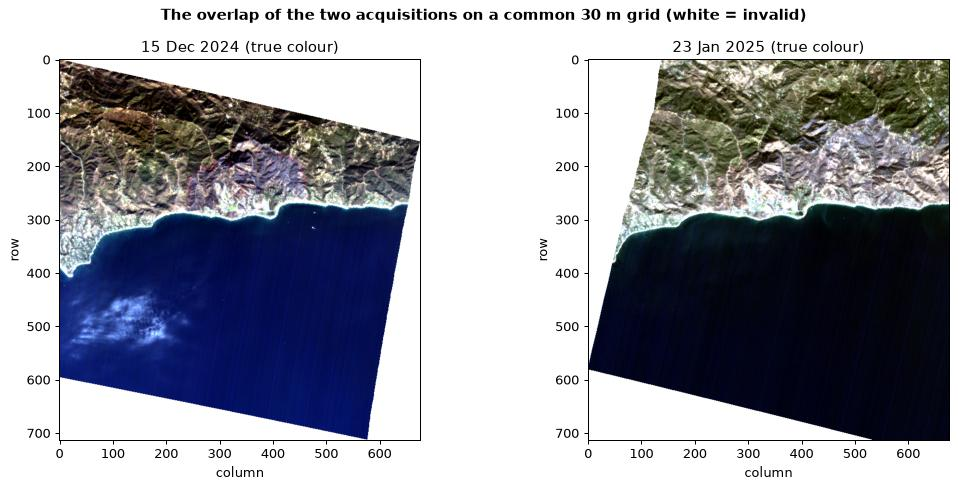

In [4]:
BANDS = {"blue": 480, "green": 560, "red": 665, "nir": 860, "swir1": 1650, "swir2": 2200}
b_pre = {k: pre.read_band(nm, win_pre, mask=False) for k, nm in BANDS.items()}
b_post = {k: post.read_band(nm, win_post, mask=False) for k, nm in BANDS.items()}

valid_pre = pre.valid_mask(win_pre)
valid_post = post.valid_mask(win_post)
valid = valid_pre & valid_post
water = (hu.nd(b_pre["green"], b_pre["nir"]) > 0) | (hu.nd(b_post["green"], b_post["nir"]) > 0)
land = valid & ~water
print(f"valid on both dates: {valid.mean() * 100:.1f}% of the overlap,  land: {land.mean() * 100:.1f}%")

rgb_pre, rgb_post = pre.rgb(win_pre), post.rgb(win_post)
for rgb, v in ((rgb_pre, valid_pre), (rgb_post, valid_post)):
    rgb[~v] = 1.0
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
ax[0].imshow(rgb_pre); ax[0].set_title("15 Dec 2024 (true colour)")
ax[1].imshow(rgb_post); ax[1].set_title("23 Jan 2025 (true colour)")
for a in ax:
    a.set_xlabel("column"); a.set_ylabel("row")
plt.suptitle("The overlap of the two acquisitions on a common 30 m grid (white = invalid)", fontweight="bold")
plt.tight_layout(); plt.show()

Even at this stage there are things to notice. In December a patch of **haze or low cloud** sits over the ocean
in the lower left. In January some land pixels are white because the **cirrus mask** removed them. Keep both in mind
when reading the change maps.

## 2. Co-registration check with FFT phase correlation

Sharing a grid on paper does not guarantee the images line up on the ground. Orthorectification errors of a
fraction of a pixel to a few pixels are common, and a misregistration of even ½ pixel creates false
"change" along every edge: field borders, roads and ridge lines.

**Phase correlation** (Kuglin & Hines, 1975) measures the translation between two images in one step. If
$B(x) = A(x - \Delta)$, the Fourier shift theorem gives $\hat B = \hat A\, e^{-2\pi i k\Delta}$, and the normalised cross-power spectrum

$$R(k) = \frac{\hat A(k)\,\hat B^*(k)}{|\hat A(k)\,\hat B^*(k)|} = e^{2\pi i k \Delta}$$

is a pure phase ramp. Its inverse FFT is a sharp peak located at the shift $\Delta$. Fitting a parabola through the peak
and its two neighbours gives **sub-pixel** precision.

The method uses only image *structure* (topography, shading, roads), so it keeps working when a minority of pixels
has genuinely changed.

artificial shift (+3, −5) px recovered as (+3.00, -5.00)
December vs January (whole land area): dy = -0.53 px, dx = -1.18 px  (peak height 0.14)

10 land tiles: dy from -1.00 to -0.16, dx from -1.98 to -0.23 px
median shift: dy = -0.59 px, dx = -0.82 px  →  ≈ 30 m


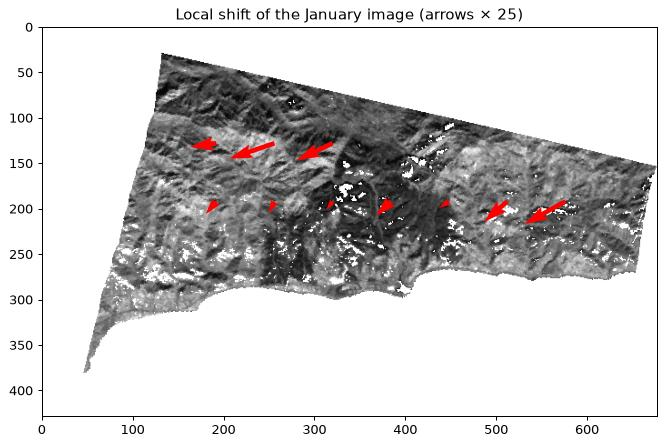

In [5]:
def phase_correlation(a, b, upsample_fit=True):
    """Shift (dy, dx) in pixels that best aligns image b to image a, and the peak height (0–1)."""
    a = np.where(np.isfinite(a), a, np.nanmean(a)); a = a - a.mean()
    b = np.where(np.isfinite(b), b, np.nanmean(b)); b = b - b.mean()
    win = np.outer(np.hanning(a.shape[0]), np.hanning(a.shape[1]))  # taper the edges to reduce FFT artifacts
    R = np.fft.fft2(a * win) * np.conj(np.fft.fft2(b * win))
    R /= np.abs(R) + 1e-12
    corr = np.fft.ifft2(R).real
    py, px = np.unravel_index(np.argmax(corr), corr.shape)
    ny, nx = corr.shape
    shift = []
    for axis, (p, n) in enumerate(((py, ny), (px, nx))):
        d = float(p)
        if upsample_fit:  # parabola through the peak and its two neighbours (with wrap-around)
            if axis == 0:
                v = corr[(p - 1) % n, px], corr[p, px], corr[(p + 1) % n, px]
            else:
                v = corr[py, (p - 1) % n], corr[py, p], corr[py, (p + 1) % n]
            denom = v[0] - 2 * v[1] + v[2]
            d += 0.5 * (v[0] - v[2]) / denom if denom != 0 else 0.0
        if d > n / 2:
            d -= n  # peaks in the second half of the axis are negative shifts
        shift.append(d)
    return tuple(shift), corr.max()


# Land sub-area (the ocean has no structure to correlate)
rs, cs = slice(20, 300), slice(100, 600)
A = b_pre["nir"][rs, cs]
B = b_post["nir"][rs, cs]

# 1) Sanity check: a known artificial shift must be recovered
test_shift, _ = phase_correlation(np.roll(A, (3, -5), axis=(0, 1)), A)
print(f"artificial shift (+3, −5) px recovered as ({test_shift[0]:+.2f}, {test_shift[1]:+.2f})")

# 2) The real pair, over the whole land area
(sy, sx), peak = phase_correlation(A, B)
print(f"December vs January (whole land area): dy = {sy:+.2f} px, dx = {sx:+.2f} px  (peak height {peak:.2f})")

# 3) Is the shift the same everywhere? Estimate it on overlapping 128 × 128 px land tiles
TILE = 128
local = []
for r0 in range(0, H - TILE + 1, TILE // 2):
    for c0 in range(0, W - TILE + 1, TILE // 2):
        sl = (slice(r0, r0 + TILE), slice(c0, c0 + TILE))
        if land[sl].mean() < 0.8:
            continue          # need mostly land for a reliable estimate
        (ty, tx), tp = phase_correlation(b_pre["nir"][sl], b_post["nir"][sl])
        local.append(dict(row=r0 + TILE // 2, col=c0 + TILE // 2, dy=ty, dx=tx, peak=tp))
local = pd.DataFrame(local)
SHIFT = (float(local.dy.median()), float(local.dx.median()))
print(f"\n{len(local)} land tiles: dy from {local.dy.min():+.2f} to {local.dy.max():+.2f}, "
      f"dx from {local.dx.min():+.2f} to {local.dx.max():+.2f} px")
print(f"median shift: dy = {SHIFT[0]:+.2f} px, dx = {SHIFT[1]:+.2f} px  →  ≈ {np.hypot(*SHIFT) * 30:.0f} m")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.imshow(np.where(land, b_pre["nir"], np.nan), cmap="gray", vmin=0, vmax=0.4)
q = ax.quiver(local.col, local.row, local.dx, -local.dy, color="red", angles="xy", scale_units="xy", scale=1 / 25)
ax.set_title("Local shift of the January image (arrows × 25)"); ax.set_xlim(0, W); ax.set_ylim(H * 0.6, 0)
plt.tight_layout(); plt.show()

The January image is offset from the December one by **about one pixel (≈ 30 m)**, with the larger component east–west,
and the local estimates vary between roughly 0.2 and 2 pixels across the area. For change detection this matters: a 1-pixel shift along a ridge line makes the sunlit slope of one date sit on
top of the shaded slope of the other date, and that creates false change.

Why would two ortho products disagree? December was acquired 7° off-nadir and January 20° off-nadir. Over mountains,
any error in the elevation model used for orthorectification moves pixels sideways by roughly
*elevation error × tan(view zenith angle)*, so the steeper view is more affected. Local variation in the offset is a sign
of this terrain effect.

We correct the **median shift** with a sub-pixel (bilinear) shift of the January data. Tools such as AROSICS
(Scheffler et al., 2017) go further and estimate and apply a spatially varying shift field.

> The peak height tells you how reliable an estimate is. Values close to 1 mean identical structure; values near
> 0.05 mean there is almost nothing in common (clouds, water, or a scene that really is different).

In [6]:
def shift_image(img, shift):
    """Sub-pixel shift (bilinear) that ignores NaNs: shift values and weights, then renormalise.

    img: 2-D (rows, cols) or 3-D (bands, rows, cols); shift: (dy, dx) or (0, dy, dx) for cubes.
    """
    ok = np.isfinite(img)
    num = ndimage.shift(np.where(ok, img, 0.0), shift, order=1, mode="constant", cval=0.0)
    den = ndimage.shift(ok.astype("float32"), shift, order=1, mode="constant", cval=0.0)
    return np.where(den > 0.99, num / np.maximum(den, 1e-6), np.nan).astype("float32")

b_post_raw = b_post                                   # keep the uncorrected bands for comparison (section 10)
land_raw = land
b_post = {k: shift_image(v, SHIFT) for k, v in b_post_raw.items()}
valid_post = np.isfinite(shift_image(np.where(valid_post, 1.0, np.nan), SHIFT))
valid = valid_pre & valid_post
water = (hu.nd(b_pre["green"], b_pre["nir"]) > 0) | (hu.nd(b_post["green"], b_post["nir"]) > 0)
land = valid & ~water

(ry, rx), _ = phase_correlation(b_pre["nir"][rs, cs], b_post["nir"][rs, cs])
both = land & land_raw
r_before = np.corrcoef(b_pre["nir"][both], b_post_raw["nir"][both])[0, 1]
r_after = np.corrcoef(b_pre["nir"][both], b_post["nir"][both])[0, 1]
print(f"residual shift after correction: dy = {ry:+.2f}, dx = {rx:+.2f} px")
print(f"pixel-wise correlation of NIR between the dates over land: {r_before:.3f} → {r_after:.3f}")

residual shift after correction: dy = +0.10, dx = -0.27 px
pixel-wise correlation of NIR between the dates over land: 0.669 → 0.692


After the correction the residual shift is a fraction of a pixel and the two dates agree better pixel by pixel. From here
on, `b_post` holds the co-registered January bands; the uncorrected ones are kept in `b_post_raw` so that section 10 can
measure what the correction bought us.

## 3. Bi-temporal burn mapping with dNBR

The **Normalized Burn Ratio** contrasts NIR, which is high for healthy leaves, with SWIR-2, which is high for dry soil,
ash and charred material:

$$\text{NBR} = \frac{\rho_{860} - \rho_{2200}}{\rho_{860} + \rho_{2200}}, \qquad
\text{dNBR} = \text{NBR}_{\text{before}} - \text{NBR}_{\text{after}}$$

A fire drops NIR and raises SWIR-2, so NBR falls and **dNBR is positive**. The USGS FIREMON protocol
(Key & Benson, 2006) sorts dNBR into severity classes:

| dNBR | Class |
|---|---|
| < −0.25 | Enhanced regrowth (high) |
| −0.25 … −0.10 | Enhanced regrowth (low) |
| −0.10 … +0.10 | Unburned |
| +0.10 … +0.27 | Low severity |
| +0.27 … +0.44 | Moderate-low severity |
| +0.44 … +0.66 | Moderate-high severity |
| > +0.66 | High severity |

These thresholds were calibrated on Landsat and on field plots (the Composite Burn Index). They are a **starting point,
not a law of nature**, and section 9 shows how sensitive the result is to them.

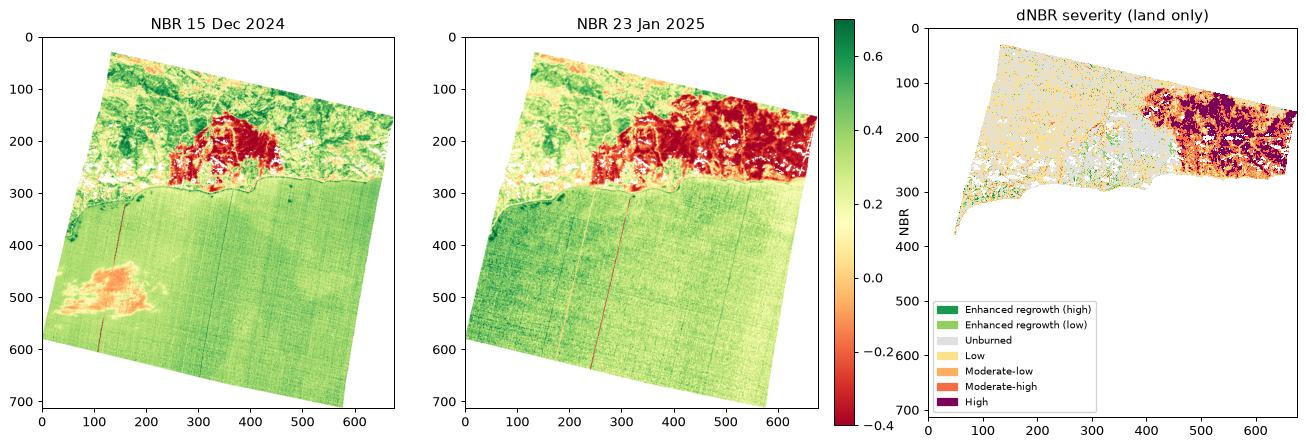

,class,pixels,area_ha,share_of_land_%
0,Enhanced regrowth (high),471,42.0,0.4
1,Enhanced regrowth (low),4097,369.0,3.8
2,Unburned,44087,3968.0,41.4
3,Low,26428,2379.0,24.8
4,Moderate-low,8424,758.0,7.9
5,Moderate-high,10920,983.0,10.2
6,High,12167,1095.0,11.4


In [7]:
nbr_pre = hu.nd(b_pre["nir"], b_pre["swir2"])
nbr_post = hu.nd(b_post["nir"], b_post["swir2"])
dnbr = np.where(land, nbr_pre - nbr_post, np.nan)

SEV_EDGES = [-np.inf, -0.25, -0.10, 0.10, 0.27, 0.44, 0.66, np.inf]
SEV_NAMES = ["Enhanced regrowth (high)", "Enhanced regrowth (low)", "Unburned", "Low",
             "Moderate-low", "Moderate-high", "High"]
SEV_COLORS = ["#1a9850", "#91cf60", "#e0e0e0", "#fee08b", "#fdae61", "#f46d43", "#7b0059"]
sev = np.digitize(dnbr, SEV_EDGES[1:-1]).astype(float)
sev[~np.isfinite(dnbr)] = np.nan
sev_cmap = ListedColormap(SEV_COLORS); sev_cmap.set_bad("white")
sev_norm = BoundaryNorm(np.arange(-0.5, 7.5), 7)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, img, t in ((ax[0], nbr_pre, "NBR 15 Dec 2024"), (ax[1], nbr_post, "NBR 23 Jan 2025")):
    im = a.imshow(np.where(valid, img, np.nan), cmap="RdYlGn", vmin=-0.4, vmax=0.7); a.set_title(t)
plt.colorbar(im, ax=ax[:2], fraction=0.025, pad=0.02, label="NBR")
ax[2].imshow(sev, cmap=sev_cmap, norm=sev_norm, interpolation="nearest")
ax[2].set_title("dNBR severity (land only)")
ax[2].legend(handles=[Patch(color=c, label=n) for c, n in zip(SEV_COLORS, SEV_NAMES)],
             loc="lower left", fontsize=8, framealpha=0.9)
plt.show()

counts = [(np.nansum(sev == k)) for k in range(7)]
table = pd.DataFrame({"class": SEV_NAMES, "pixels": counts,
                      "area_ha": np.round(np.array(counts) * 0.09, 0),
                      "share_of_land_%": np.round(np.array(counts) / land.sum() * 100, 1)})
table

Three things stand out:

1. The December NBR (left) **already** contains one compact burn scar in the centre (red). In January (middle) a second,
   much larger low-NBR area has appeared **to its east**, and that is where dNBR is high.
2. The older scar in the centre has *low NBR on both dates*, so its dNBR is close to zero. This is a fundamental
   limitation of bi-temporal change detection: **dNBR measures what changed between the two dates, not what is
   burned.** The December image was taken *after* the Franklin fire (9–10 December 2024), so it cannot reveal that fire.
   Only the Palisades fire (from 7 January 2025) falls between the two acquisitions.
3. Much of the unburned land in the west is classed as **"Low" severity**. Is that a real low-severity burn, or a
   systematic difference between the two images? Section 6 investigates and section 10 corrects it.

## 4. Is the new burn scar real? Checking with the data

Before believing a change map, confirm it **independently**:

1. **Where is it?** Convert the pixels to longitude/latitude and compare with what is known about the event.
2. **What does it look like?** A SWIR–NIR–red false-colour composite shows fresh burn scars in dark red/brown.
3. **What is its spectrum?** A real burn scar should look like *other* burn scars: loss of the red edge and the NIR
   plateau, weaker leaf-water absorptions at 980/1200 nm, and SWIR reflectance rising towards 2200 nm.
   We compare the new scar with the Franklin scar, which was already burned in December, and with vegetation that stayed unburned.

In [8]:
# The largest connected region of moderate-or-higher dNBR = the candidate new burn scar
burn_candidate = np.nan_to_num(dnbr) > 0.27
labels_cc, n_cc = ndimage.label(burn_candidate)
sizes = ndimage.sum(burn_candidate, labels_cc, index=np.arange(1, n_cc + 1))
new_burn = labels_cc == (np.argmax(sizes) + 1)
# The December burn scar (Franklin fire): low NBR already in December
old_burn = land & (nbr_pre < -0.05) & (nbr_post < -0.05)
old_burn = ndimage.binary_opening(old_burn, iterations=1)
# Stable vegetation: high NBR on both dates
stable_veg = land & (nbr_pre > 0.3) & (np.abs(nbr_pre - nbr_post) < 0.05)

def describe(mask, name, scene, win):
    rows, cols = np.nonzero(mask)
    lon, lat = scene.rowcol_to_lonlat(rows + win[0], cols + win[2])
    print(f"{name:24s} {mask.sum():6d} px = {mask.sum() * 0.09:6.0f} ha | centre {-np.median(lon):.3f}°W "
          f"{np.median(lat):.3f}°N | spans {-np.percentile(lon, 98):.3f}–{-np.percentile(lon, 2):.3f}°W")

describe(new_burn, "New burn (Dec → Jan)", pre, win_pre)
describe(old_burn, "Burned before 15 Dec", pre, win_pre)
describe(stable_veg, "Stable vegetation", pre, win_pre)
print(f"\n{n_cc} connected regions with dNBR > 0.27; the largest holds "
      f"{new_burn.sum() / burn_candidate.sum() * 100:.0f}% of those pixels")

New burn (Dec → Jan)      28115 px =   2530 ha | centre 118.637°W 34.061°N | spans 118.598–118.679°W
Burned before 15 Dec      12540 px =   1129 ha | centre 118.695°W 34.052°N | spans 118.665–118.731°W
Stable vegetation          5911 px =    532 ha | centre 118.740°W 34.074°N | spans 118.657–118.782°W

1349 connected regions with dNBR > 0.27; the largest holds 89% of those pixels


**Where:** the new scar is centred around 118.63–118.64 °W, 34.06 °N, and runs to the eastern edge of the overlap
(≈118.59 °W). Its location and timing match the documented **western part of the Palisades fire**, which started on
7 January 2025 in Pacific Palisades and burned west through Topanga State Park and into eastern Malibu. The older scar
around 118.70 °W, 34.05 °N matches the **Franklin fire** (Malibu Canyon / Pepperdine, 9–10 December 2024).
*Check these statements yourself against the official CAL FIRE perimeters (exercise 2).*

Now look at the images and the spectra.

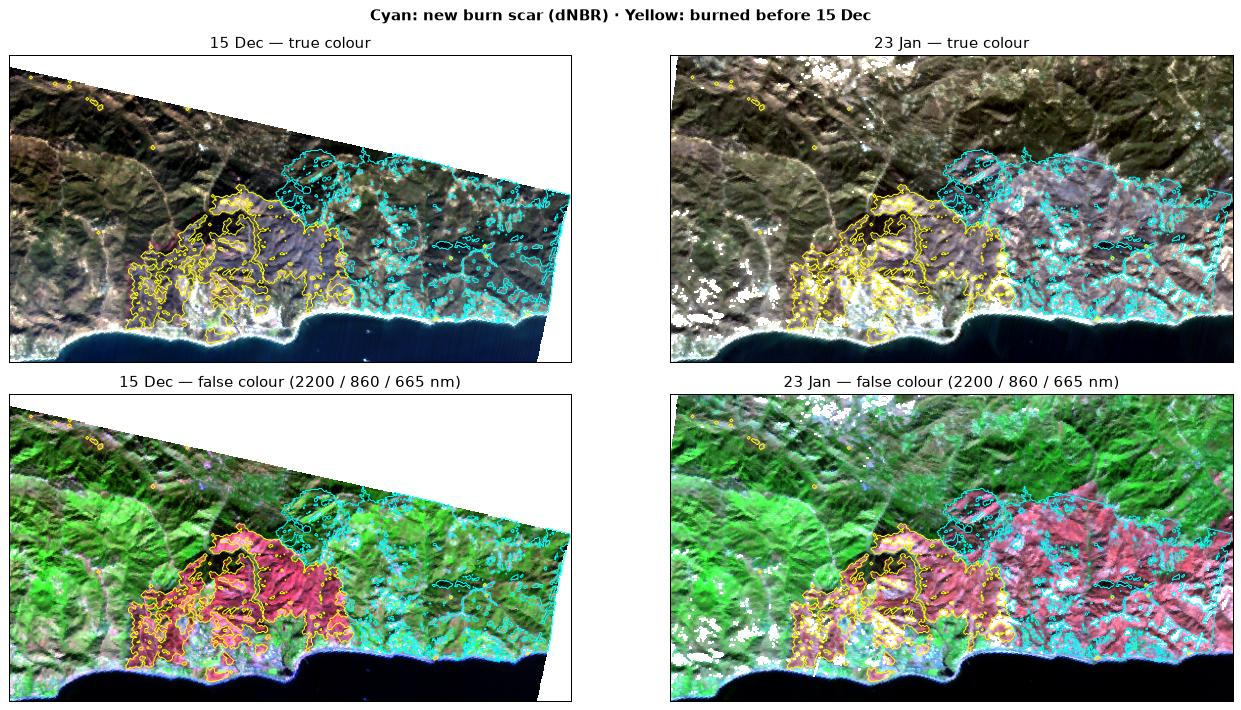

In [9]:
rows, cols = np.nonzero(new_burn | old_burn)
box = (max(rows.min() - 20, 0), min(rows.max() + 20, H), max(cols.min() - 20, 0), min(cols.max() + 20, W))
sub_pre = (win_pre[0] + box[0], win_pre[0] + box[1], win_pre[2] + box[2], win_pre[2] + box[3])
sub_post = (win_post[0] + box[0], win_post[0] + box[1], win_post[2] + box[2], win_post[2] + box[3])

fc = (2200, 860, 665)  # SWIR-2, NIR, red: vegetation green, fresh burn dark red/brown, soil pink
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
ax[0, 0].imshow(pre.rgb(sub_pre)); ax[0, 0].set_title("15 Dec — true colour")
ax[0, 1].imshow(post.rgb(sub_post)); ax[0, 1].set_title("23 Jan — true colour")
ax[1, 0].imshow(pre.rgb(sub_pre, wl=fc)); ax[1, 0].set_title("15 Dec — false colour (2200 / 860 / 665 nm)")
ax[1, 1].imshow(post.rgb(sub_post, wl=fc)); ax[1, 1].set_title("23 Jan — false colour (2200 / 860 / 665 nm)")
for a in ax.flat:
    a.contour(new_burn[box[0]:box[1], box[2]:box[3]], levels=[0.5], colors="cyan", linewidths=0.8)
    a.contour(old_burn[box[0]:box[1], box[2]:box[3]], levels=[0.5], colors="yellow", linewidths=0.8)
    a.set_xticks([]); a.set_yticks([])
plt.suptitle("Cyan: new burn scar (dNBR) · Yellow: burned before 15 Dec", fontweight="bold")
plt.tight_layout(); plt.show()

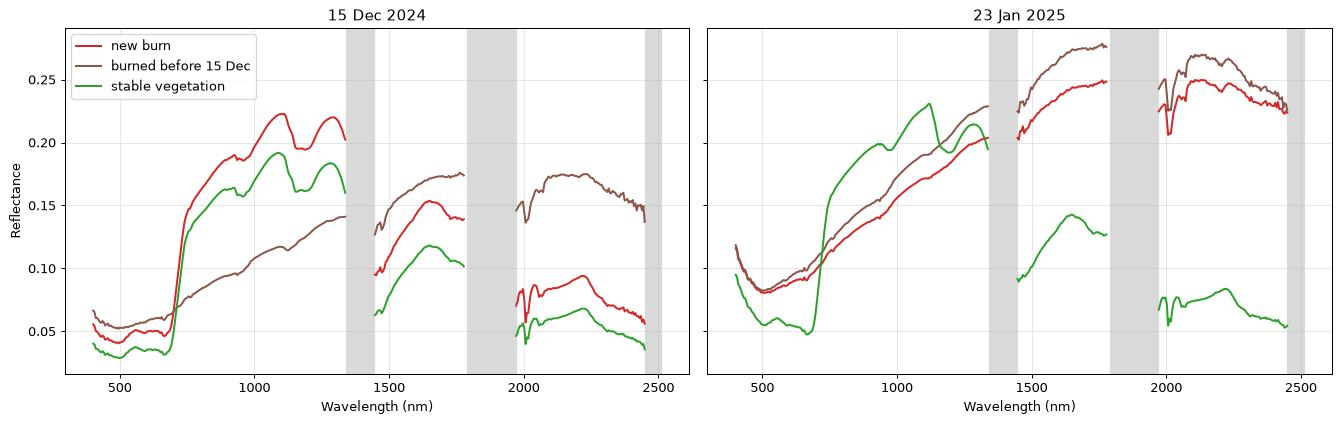

Spectral angle (degrees) — smaller = more similar shape
  new burn in Jan   vs  old burn in Dec      :   1.7°
  new burn in Jan   vs  stable veg in Jan    :  31.9°
  new burn in Dec   vs  stable veg in Dec    :   4.1°


In [10]:
def group_mean_spectrum(scene, win, mask, box, shift=None, max_px=3000, seed=0):
    """Mean full spectrum of the mask pixels inside box (overlap coordinates)."""
    cube, wl = scene.read_cube((win[0] + box[0], win[0] + box[1], win[2] + box[2], win[2] + box[3]))
    if shift is not None:                      # apply the co-registration correction (January)
        cube = shift_image(cube, (0,) + tuple(shift))
    m = mask[box[0]:box[1], box[2]:box[3]]
    X = cube[:, m].T
    X = X[np.all(np.isfinite(X), axis=1)]
    if len(X) > max_px:
        X = X[np.random.default_rng(seed).choice(len(X), max_px, replace=False)]
    return wl, X.mean(axis=0)

spectra = {}
for name, mask in (("new burn", new_burn), ("burned before 15 Dec", old_burn), ("stable vegetation", stable_veg)):
    r, c = np.nonzero(mask)
    gbox = (r.min(), r.max() + 1, c.min(), c.max() + 1)
    wl, spectra[(name, "Dec")] = group_mean_spectrum(pre, win_pre, mask, gbox)
    _, spectra[(name, "Jan")] = group_mean_spectrum(post, win_post, mask, gbox, shift=SHIFT)

colors = {"new burn": "tab:red", "burned before 15 Dec": "tab:brown", "stable vegetation": "tab:green"}
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for k, date in enumerate(("Dec", "Jan")):
    for name in colors:
        hu.plot_spectrum(ax[k], wl, spectra[(name, date)], color=colors[name], lw=1.6, label=name)
    hu.shade_bad_regions(ax[k]); ax[k].set_title({"Dec": "15 Dec 2024", "Jan": "23 Jan 2025"}[date])
    ax[k].set_xlabel("Wavelength (nm)"); ax[k].grid(alpha=0.3)
ax[0].set_ylabel("Reflectance"); ax[0].legend()
plt.tight_layout(); plt.show()

ang = lambda s1, s2: np.degrees(hu.spectral_angle(s1[None], s2)[0])
print("Spectral angle (degrees) — smaller = more similar shape")
print(f"  new burn in Jan   vs  old burn in Dec      : {ang(spectra[('new burn', 'Jan')], spectra[('burned before 15 Dec', 'Dec')]):5.1f}°")
print(f"  new burn in Jan   vs  stable veg in Jan    : {ang(spectra[('new burn', 'Jan')], spectra[('stable vegetation', 'Jan')]):5.1f}°")
print(f"  new burn in Dec   vs  stable veg in Dec    : {ang(spectra[('new burn', 'Dec')], spectra[('stable vegetation', 'Dec')]):5.1f}°")

Three independent lines of evidence point the same way:

- In **December** the pixels of the future scar have a spectrum close to the unburned vegetation, with a red edge and
  a NIR plateau. In **January** they look almost the same as the Franklin scar did in December: a flat NIR, no red edge,
  and a SWIR that rises towards 2200 nm. The spectral angles make this quantitative.
- The false-colour composite shows the typical dark-red fresh-burn signature *inside* the cyan outline only.
- The location and date match an independently documented event.

Together these give strong evidence that the change is a real burn scar and not a processing artifact.

## 5. Change vector analysis on full spectra (tiled)

dNBR uses 2 of Tanager's 352 good bands. **Change vector analysis** (CVA; Malila, 1980) uses them all. For each pixel
the change vector is $\Delta\boldsymbol\rho = \boldsymbol\rho_{\text{after}} - \boldsymbol\rho_{\text{before}}$ and we look at

- its **magnitude** $\|\Delta\boldsymbol\rho\| / \sqrt{n}$ (the RMS reflectance change): *how much* changed, and
- the **spectral angle** between the two spectra: how much the spectral *shape* changed. Pure brightness changes,
  such as a different illumination or view angle, leave the angle almost untouched.
- the **direction**: which part of the spectrum changed. A burn lowers NIR and raises SWIR-2, green-up does the
  opposite, and illumination changes scale everything together.

Reading two full cubes of the overlap at once would take ~1.3 GB, so we process in **tiles of 64 rows**. In the same pass
we also simulate what Sentinel-2 would have measured, which we need in section 7.

In [11]:
S2 = hu.SENTINEL2_BANDS
s2_names = list(S2)
s2_c = [S2[k][0] for k in s2_names]
s2_w = [S2[k][1] for k in s2_names]

def read_post_tile(r0, r1, margin=3):
    """January rows r0:r1 of the overlap, co-registered (read a margin so the shift has data to pull in)."""
    rr0, rr1 = max(r0 - margin, 0), min(r1 + margin, H)
    cube, wl = post.read_cube((win_post[0] + rr0, win_post[0] + rr1, win_post[2], win_post[3]))
    cube = shift_image(cube, (0,) + SHIFT)
    return cube[:, r0 - rr0: r0 - rr0 + (r1 - r0)], wl

def tiled_change(tile_rows=64):
    out = {k: np.full((H, W), np.nan, "float32") for k in
           ("mag", "angle", "d_vis", "d_nir", "d_swir2", "nbr_s2_pre", "nbr_s2_post")}
    for r0 in range(0, H, tile_rows):
        r1 = min(r0 + tile_rows, H)
        ca, wl = pre.read_cube((win_pre[0] + r0, win_pre[0] + r1, win_pre[2], win_pre[3]))
        cb, _ = read_post_tile(r0, r1)
        ca[:, ~valid[r0:r1]] = np.nan
        d = cb - ca
        out["mag"][r0:r1] = np.sqrt(np.nanmean(d ** 2, axis=0))
        dot = np.nansum(ca * cb, axis=0)
        norm = np.sqrt(np.nansum(ca ** 2, axis=0) * np.nansum(cb ** 2, axis=0)) + 1e-12
        out["angle"][r0:r1] = np.degrees(np.arccos(np.clip(dot / norm, -1, 1)))
        out["d_vis"][r0:r1] = np.nanmean(d[(wl > 450) & (wl < 680)], axis=0)
        out["d_nir"][r0:r1] = np.nanmean(d[(wl > 780) & (wl < 900)], axis=0)
        out["d_swir2"][r0:r1] = np.nanmean(d[(wl > 2100) & (wl < 2300)], axis=0)
        for key, cube in (("nbr_s2_pre", ca), ("nbr_s2_post", cb)):
            X = cube.reshape(len(wl), -1).T
            s2 = hu.resample_to_sensor(wl, X, s2_c, s2_w)
            b8a, b12 = s2[:, s2_names.index("B8A")], s2[:, s2_names.index("B12")]
            out[key][r0:r1] = hu.nd(b8a, b12).reshape(r1 - r0, W)
    for k in out:
        out[k][~valid] = np.nan
    return out

t0 = time.perf_counter()
cva = tiled_change()
print(f"tiled change pass over {H}×{W} px × 352 bands × 2 dates: {time.perf_counter() - t0:.1f} s")

tiled change pass over 713×677 px × 352 bands × 2 dates: 22.8 s


burn-like (NIR↓ SWIR↑)      :  84.6% inside the new scar |   7.0% of the land outside it
green-up-like (NIR↑ SWIR↓)  :   0.0% inside the new scar |   2.4% of the land outside it
brightness / other          :  15.3% inside the new scar |  81.4% of the land outside it
little change               :   0.1% inside the new scar |   9.2% of the land outside it
land outside the scar that became brighter in VIS, NIR and SWIR-2 at once: 82%


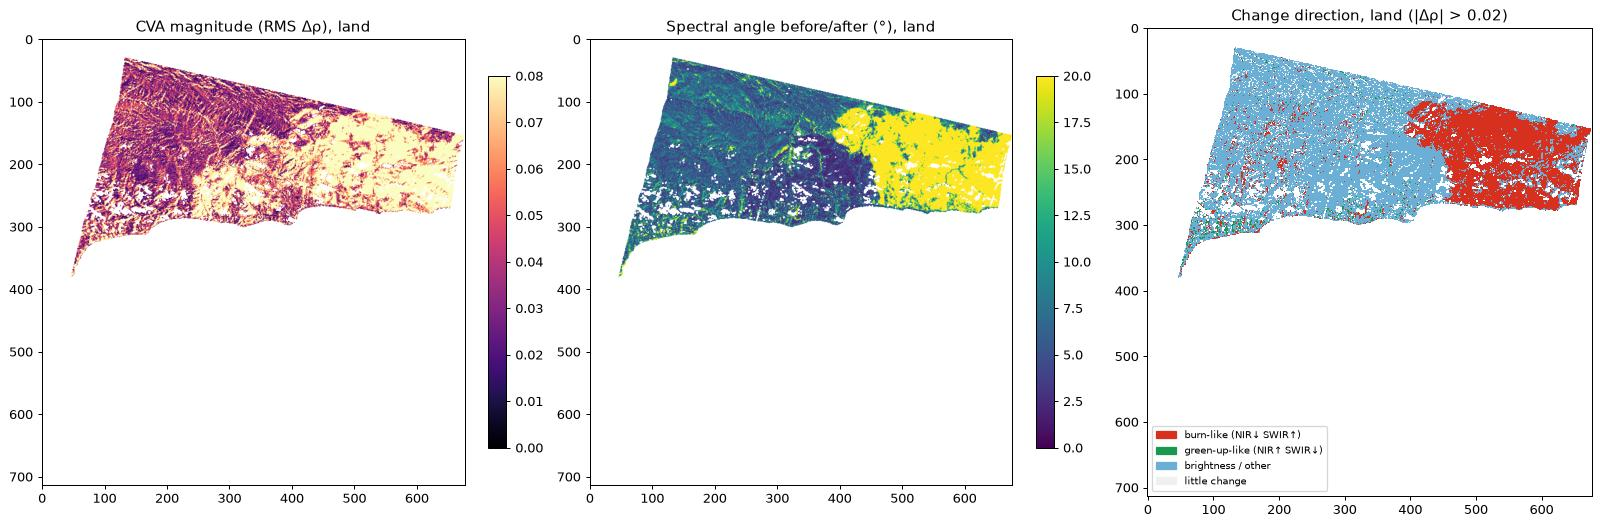

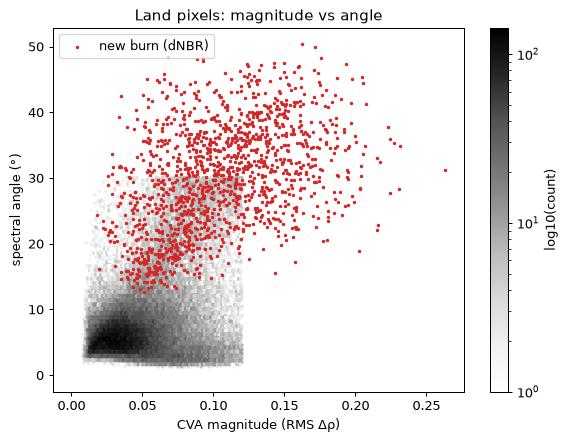

In [12]:
# Change direction: burn = NIR down & SWIR-2 up; green-up = NIR up & SWIR-2 down; else brightness/other
direction = np.full((H, W), np.nan)
significant = cva["mag"] > 0.02
direction[significant & (cva["d_nir"] < 0) & (cva["d_swir2"] > 0)] = 0      # burn-like
direction[significant & (cva["d_nir"] > 0) & (cva["d_swir2"] < 0)] = 1      # green-up-like
direction[significant & np.isnan(direction)] = 2                            # brighter/darker overall
direction[~significant & valid] = 3                                         # little change
dir_names = ["burn-like (NIR↓ SWIR↑)", "green-up-like (NIR↑ SWIR↓)", "brightness / other", "little change"]
dir_colors = ["#d7301f", "#1a9850", "#6baed6", "#f0f0f0"]

outside = land & ~new_burn
for k, n in enumerate(dir_names):
    print(f"{n:28s}: {np.mean(direction[new_burn] == k) * 100:5.1f}% inside the new scar | "
          f"{np.mean(direction[outside] == k) * 100:5.1f}% of the land outside it")
brighter = outside & (cva["d_vis"] > 0) & (cva["d_nir"] > 0) & (cva["d_swir2"] > 0)
print(f"land outside the scar that became brighter in VIS, NIR and SWIR-2 at once: "
      f"{brighter.sum() / outside.sum() * 100:.0f}%")

fig, ax = plt.subplots(1, 3, figsize=(18, 5.8))
im0 = ax[0].imshow(np.where(land, cva["mag"], np.nan), cmap="magma", vmin=0, vmax=0.08)
ax[0].set_title("CVA magnitude (RMS Δρ), land"); plt.colorbar(im0, ax=ax[0], fraction=0.04)
im1 = ax[1].imshow(np.where(land, cva["angle"], np.nan), cmap="viridis", vmin=0, vmax=20)
ax[1].set_title("Spectral angle before/after (°), land"); plt.colorbar(im1, ax=ax[1], fraction=0.04)
dcm = ListedColormap(dir_colors); dcm.set_bad("white")
ax[2].imshow(np.where(land, direction, np.nan), cmap=dcm, vmin=-0.5, vmax=3.5, interpolation="nearest")
ax[2].set_title("Change direction, land (|Δρ| > 0.02)")
ax[2].legend(handles=[Patch(color=c, label=n) for c, n in zip(dir_colors, dir_names)], loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

m = land & np.isfinite(cva["angle"])
fig, ax = plt.subplots(figsize=(6.5, 5))
hb = ax.hexbin(cva["mag"][m], cva["angle"][m], gridsize=80, bins="log", cmap="Greys", extent=(0, 0.12, 0, 30))
ax.scatter(cva["mag"][new_burn & m][::20], cva["angle"][new_burn & m][::20], s=3, c="tab:red", label="new burn (dNBR)")
ax.set_xlabel("CVA magnitude (RMS Δρ)"); ax.set_ylabel("spectral angle (°)"); ax.legend(loc="upper left")
ax.set_title("Land pixels: magnitude vs angle"); plt.colorbar(hb, label="log10(count)"); plt.tight_layout(); plt.show()

- The **new scar** stands out in all three maps: a large magnitude, a large angle (the spectral *shape* changed) and a
  burn-like direction.
- Outside the scar, the dominant change is **brightness**. Most of the unburned land became brighter in the visible, NIR
  and SWIR at the same time, and only a small part greened up. When every band goes up together, the land cover did not
  change. The likely causes are the different viewing and illumination geometry (December 7° off-nadir, January 20°)
  and differences in the atmospheric correction of the two dates (section 6).
- In the magnitude-vs-angle plot the burn pixels separate clearly by **angle**, while many unburned pixels have a
  moderate magnitude but a small angle: they changed brightness, not shape. The texture that follows the ridges in the
  magnitude map is the same effect, since sunlit and shaded slopes respond differently to a change in geometry.

> CVA does not replace the index; it complements it. The angle and the direction help separate a real **land-cover change**
> from a change in **illumination or phenology**.

## 6. What the change map gets wrong: artifacts

An honest analysis also reports where the method fails. Here we look at **all valid pixels**, including the ocean,
to see the artifacts that the land mask was hiding.

sun zenith   : 58.6° (Dec)  vs 55.9° (Jan)
view zenith  : 7.3° (Dec)  vs 20.3° (Jan)
cloud-flagged pixels in the December overlap: 27
cirrus-flagged (January) but valid in December: 3441 px


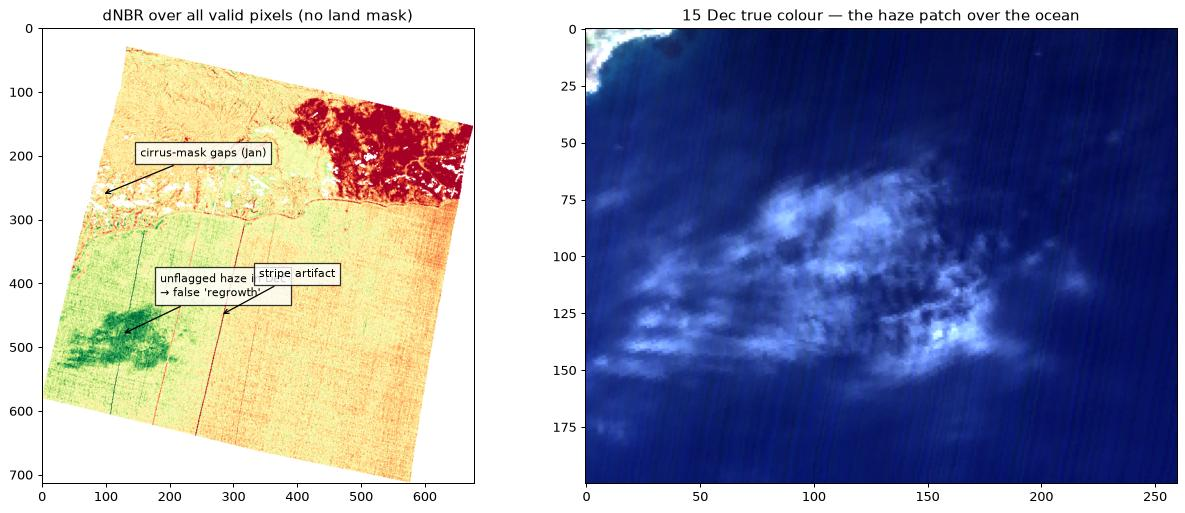

In [13]:
dnbr_all = np.where(valid, nbr_pre - nbr_post, np.nan)
sza_pre = np.nanmean(pre.read_field("sun_zenith", win_pre)); sza_post = np.nanmean(post.read_field("sun_zenith", win_post))
vza_pre = np.nanmean(pre.read_field("sensor_zenith", win_pre)); vza_post = np.nanmean(post.read_field("sensor_zenith", win_post))
print(f"sun zenith   : {sza_pre:.1f}° (Dec)  vs {sza_post:.1f}° (Jan)")
print(f"view zenith  : {vza_pre:.1f}° (Dec)  vs {vza_post:.1f}° (Jan)")
print(f"cloud-flagged pixels in the December overlap: {pre.masks(win_pre)['cloud'].sum()}")

# where does the January cirrus mask remove pixels that are valid in December?
cirrus_gap = post.masks(win_post)["cirrus"] & valid_pre
gap_lab, n_gap = ndimage.label(ndimage.binary_dilation(cirrus_gap, iterations=3))
gap_r, gap_c = ndimage.center_of_mass(cirrus_gap, gap_lab, np.argmax(np.bincount(gap_lab.ravel())[1:]) + 1)
print(f"cirrus-flagged (January) but valid in December: {cirrus_gap.sum()} px")

fig, ax = plt.subplots(1, 2, figsize=(14, 5.8))
ax[0].imshow(dnbr_all, cmap="RdYlGn_r", vmin=-0.6, vmax=0.6)
ax[0].set_title("dNBR over all valid pixels (no land mask)")
annot = [((480, 125), "unflagged haze in Dec\n→ false 'regrowth'"),
         ((450, 280), "stripe artifact"), ((gap_r, gap_c), "cirrus-mask gaps (Jan)")]
for (r, c), txt in annot:
    ax[0].annotate(txt, xy=(c, r), xytext=(c + 60, r - 60), color="k", fontsize=9,
                   arrowprops=dict(arrowstyle="->", color="k"), bbox=dict(fc="w", alpha=0.8))
zoom = (slice(380, 580), slice(20, 280))
ax[1].imshow(rgb_pre[zoom]); ax[1].set_title("15 Dec true colour — the haze patch over the ocean")
plt.tight_layout(); plt.show()

### A systematic difference: the January image is brighter

Section 5 showed that most unburned land became brighter in all bands. Let us quantify this on a **control area**:
land that is well away from the new scar (more than 30 pixels ≈ 900 m) and outside the older Franklin scar, where we are
confident nothing burned between the dates.

control area: 52,444 px (4,720 ha)
median dNBR in the control area (should be ~0 if nothing changed): +0.079
share of control pixels classed 'Low' severity or higher: 40%


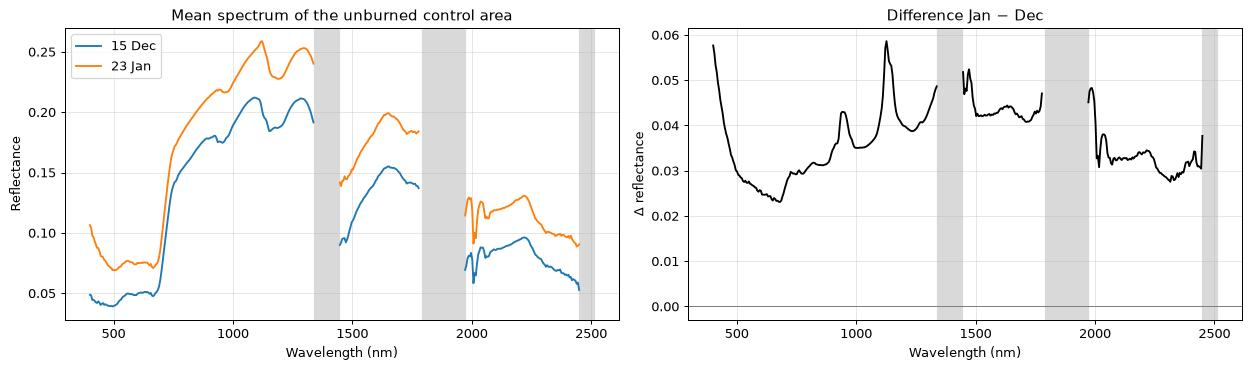

In [14]:
control = land & ~ndimage.binary_dilation(new_burn, iterations=30) & ~ndimage.binary_dilation(old_burn, iterations=5)
r, c = np.nonzero(control)
cbox = (r.min(), r.max() + 1, c.min(), c.max() + 1)
wl, ctrl_dec = group_mean_spectrum(pre, win_pre, control, cbox, max_px=5000)
_, ctrl_jan = group_mean_spectrum(post, win_post, control, cbox, shift=SHIFT, max_px=5000)
dnbr_offset = float(np.nanmedian(dnbr[control]))
print(f"control area: {control.sum():,} px ({control.sum() * 0.09:,.0f} ha)")
print(f"median dNBR in the control area (should be ~0 if nothing changed): {dnbr_offset:+.3f}")
print(f"share of control pixels classed 'Low' severity or higher: {np.mean(dnbr[control] > 0.10) * 100:.0f}%")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
hu.plot_spectrum(ax[0], wl, ctrl_dec, label="15 Dec"); hu.plot_spectrum(ax[0], wl, ctrl_jan, label="23 Jan")
ax[0].set_title("Mean spectrum of the unburned control area"); ax[0].set_ylabel("Reflectance"); ax[0].legend()
hu.plot_spectrum(ax[1], wl, ctrl_jan - ctrl_dec, color="k"); ax[1].axhline(0, color="0.5", lw=0.8)
ax[1].set_title("Difference Jan − Dec"); ax[1].set_ylabel("Δ reflectance")
for a in ax:
    hu.shade_bad_regions(a); a.set_xlabel("Wavelength (nm)"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Over land where nothing burned, January is brighter **across the whole spectrum**, by about 0.02–0.06 in reflectance.
Because NBR is a *normalised difference*, adding a similar amount to NIR and SWIR-2 pushes NBR towards zero. As a result the
unburned control area has a median dNBR well above zero, and a large part of it lands in the "Low severity" class.

The *shape* of the difference spectrum hints at the causes:
- it rises steeply towards the **blue**, which is typical of a difference in the aerosol (haze) correction;
- it has sharp **spikes at 940 and 1130 nm**, exactly where water vapour absorbs, which means the two dates' water-vapour
  corrections do not match perfectly;
- beneath that sits a broad offset that could come from **BRDF** effects of the different viewing geometry.

With only two images we cannot separate these contributions completely. The standard practical fix in burn
severity mapping is the **dNBR offset** (e.g. Parks et al., 2014): subtract the median dNBR of unburned land from the
whole map. We apply it in section 10 and measure what it changes.

### Summary: artifacts and remedies

| Artifact | Cause | Effect | Remedy |
|---|---|---|---|
| **Haze / low cloud over the ocean** in December | Missed by the beta cloud mask | Large false dNBR | Always inspect the imagery; add a haze test (e.g. blue reflectance or a cirrus/aerosol threshold); mask water |
| **Diagonal stripe** | A detector column with a small calibration error, rotated by the orthorectification | Thin false line in every product | Destriping (column-wise normalisation); ignore thin linear features |
| **Cirrus-mask gaps** in January | Conservative cirrus flag over bright slopes | Missing data | Check what the mask removes; relax it if it is mostly false positives |
| **Systematic brightening** of January | Geometry (BRDF) and/or atmospheric-correction differences | Unburned land shifted into "Low severity" | dNBR offset from an unburned control area; relative normalisation |
| **Misregistration** (1–2 px) | Orthorectification over terrain, different view angles | False change along ridges and edges | Co-registration (section 2) |
| **Different geometry** (view 7° vs 20°, sun 59° vs 56°) | BRDF and topographic shading | Brightness changes on slopes | Shape-based metrics (angle, ratios); topographic correction with a DEM |
| **Earlier burn** (Franklin) | Burned before the first image | Not detected | Pick a true pre-fire image |

Water is masked for the burn analysis because NBR over water is dominated by noise (both bands are close to 0),
and a stable, non-zero ocean dNBR would be meaningless anyway.

## 7. Uncertainty: how sure are we about each pixel?

Tanager ships a per-pixel, per-band **reflectance uncertainty** (`surface_reflectance_uncertainty`, 1σ). We propagate it
into dNBR in two ways.

**Monte Carlo**: draw many plausible reflectance images $\rho + \sigma\,\varepsilon$ with $\varepsilon \sim \mathcal N(0,1)$,
recompute dNBR for each draw, and take the standard deviation across draws. It is simple, works for *any* algorithm
(classifiers included), and makes the assumptions explicit.

**Analytic** (first-order error propagation), for $\text{NBR} = (N - S)/(N + S)$:

$$\sigma_{\text{NBR}}^2 = \left(\frac{2S}{(N+S)^2}\right)^2 \sigma_N^2 + \left(\frac{2N}{(N+S)^2}\right)^2 \sigma_S^2,
\qquad \sigma_{\text{dNBR}} = \sqrt{\sigma_{\text{NBR,before}}^2 + \sigma_{\text{NBR,after}}^2}$$

Both approaches assume that errors are **independent** between bands and dates.

In [15]:
def read_unc(scene, win, nm):
    idx = [scene.band_index(nm)]
    return scene.read_cube(win, bands=idx, dataset="surface_reflectance_uncertainty", mask=False)[0][0]

u_pre = {k: read_unc(pre, win_pre, BANDS[k]) for k in ("nir", "swir2")}
u_post = {k: shift_image(read_unc(post, win_post, BANDS[k]), SHIFT) for k in ("nir", "swir2")}
print(f"median relative uncertainty over land: NIR {np.nanmedian(u_pre['nir'][land] / b_pre['nir'][land]) * 100:.2f}%, "
      f"SWIR-2 {np.nanmedian(u_pre['swir2'][land] / b_pre['swir2'][land]) * 100:.2f}%")

# Monte Carlo (running mean/variance so memory stays at one image per draw)
rng = np.random.default_rng(42)
N_DRAWS = 100
s1 = np.zeros((H, W)); s2 = np.zeros((H, W))
for _ in range(N_DRAWS):
    draw = {}
    for tag, b, u in (("pre", b_pre, u_pre), ("post", b_post, u_post)):
        n = b["nir"] + u["nir"] * rng.standard_normal((H, W))
        s = b["swir2"] + u["swir2"] * rng.standard_normal((H, W))
        draw[tag] = hu.nd(n, s)
    d = draw["pre"] - draw["post"]
    s1 += d; s2 += d ** 2
sigma_mc = np.sqrt(np.maximum(s2 / N_DRAWS - (s1 / N_DRAWS) ** 2, 0))
sigma_mc[~land] = np.nan

def sigma_nbr(N, S, sN, sS):
    return np.sqrt((2 * S / (N + S) ** 2) ** 2 * sN ** 2 + (2 * N / (N + S) ** 2) ** 2 * sS ** 2)

sigma_an = np.sqrt(sigma_nbr(b_pre["nir"], b_pre["swir2"], u_pre["nir"], u_pre["swir2"]) ** 2 +
                   sigma_nbr(b_post["nir"], b_post["swir2"], u_post["nir"], u_post["swir2"]) ** 2)
sigma_an[~land] = np.nan
print(f"σ(dNBR) median over land: Monte Carlo {np.nanmedian(sigma_mc):.4f}, analytic {np.nanmedian(sigma_an):.4f}")

median relative uncertainty over land: NIR 0.42%, SWIR-2 1.05%


σ(dNBR) median over land: Monte Carlo 0.0075, analytic 0.0076


The product uncertainty is **small**: a fraction of a percent of the reflectance, which gives σ(dNBR) of about 0.01.
If we apply the rule "change is significant where |dNBR| > 2σ", almost every land pixel counts as "significantly changed".

That does not mean every pixel really changed. The product uncertainty describes the **random noise of one acquisition**.
It says nothing about what differs *between two dates*: illumination and view geometry, phenology, residual
atmospheric-correction errors and co-registration. We estimate that between-date variability **empirically** as the
spread of dNBR over the unburned **control area** from section 6, using a robust standard deviation that is not
thrown off by a few outliers: $\sigma_{\text{emp}} = 1.4826 \cdot \text{MAD}(\text{dNBR}_{\text{control}})$.

empirical between-date σ (control area) : 0.087   vs  sensor-noise σ ≈ 0.008
'significant' with sensor noise only    :  91.0% of land,  85.6% of the unburned control area
'significant' with total σ              :  35.4% of land,  10.3% of the unburned control area
significant NBR decrease (total σ): 2,941 ha


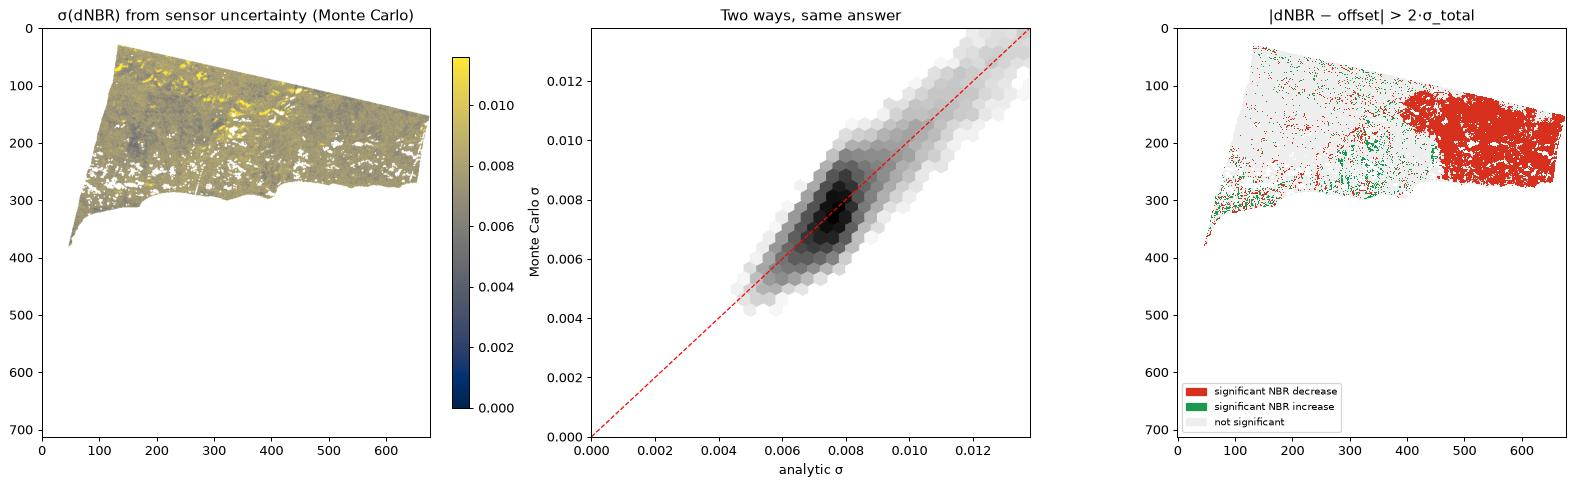

In [16]:
d_ctrl = dnbr[control]
sigma_emp = 1.4826 * np.nanmedian(np.abs(d_ctrl - np.nanmedian(d_ctrl)))
sigma_tot = np.sqrt(sigma_mc ** 2 + sigma_emp ** 2)
dev = dnbr - dnbr_offset                    # dNBR relative to unburned land (section 6)
sig_product = land & (np.abs(dev) > 2 * sigma_mc)
sig_total = land & (np.abs(dev) > 2 * sigma_tot)
print(f"empirical between-date σ (control area) : {sigma_emp:.3f}   vs  sensor-noise σ ≈ {np.nanmedian(sigma_mc):.3f}")
print(f"'significant' with sensor noise only    : {sig_product.sum() / land.sum() * 100:5.1f}% of land, "
      f"{sig_product[control].mean() * 100:5.1f}% of the unburned control area")
print(f"'significant' with total σ              : {sig_total.sum() / land.sum() * 100:5.1f}% of land, "
      f"{sig_total[control].mean() * 100:5.1f}% of the unburned control area")
print(f"significant NBR decrease (total σ): {(sig_total & (dev > 0)).sum() * 0.09:,.0f} ha")

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
im = ax[0].imshow(sigma_mc, cmap="cividis", vmin=0, vmax=np.nanpercentile(sigma_mc, 99))
ax[0].set_title("σ(dNBR) from sensor uncertainty (Monte Carlo)"); plt.colorbar(im, ax=ax[0], fraction=0.04)
ok = np.isfinite(sigma_mc) & np.isfinite(sigma_an)
ax[1].hexbin(sigma_an[ok], sigma_mc[ok], gridsize=60, bins="log", cmap="Greys")
lim = np.nanpercentile(sigma_mc, 99.5); ax[1].plot([0, lim], [0, lim], "r--", lw=1)
ax[1].set_xlim(0, lim); ax[1].set_ylim(0, lim)
ax[1].set_xlabel("analytic σ"); ax[1].set_ylabel("Monte Carlo σ"); ax[1].set_title("Two ways, same answer")
sig_map = np.full((H, W), np.nan); sig_map[land] = 0; sig_map[sig_total & (dev < 0)] = 1; sig_map[sig_total & (dev > 0)] = 2
ax[2].imshow(sig_map, cmap=ListedColormap(["#eeeeee", "#1a9850", "#d7301f"]), vmin=-0.5, vmax=2.5, interpolation="nearest")
ax[2].set_title("|dNBR − offset| > 2·σ_total")
ax[2].legend(handles=[Patch(color="#d7301f", label="significant NBR decrease"),
                      Patch(color="#1a9850", label="significant NBR increase"),
                      Patch(color="#eeeeee", label="not significant")], loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

With sensor noise alone, most of the unburned control area would count as "significantly changed", which is clearly
wrong. With the total σ it is about one pixel in ten. That is still more than the ~5 % a Gaussian 2σ test would give,
because between-date differences have heavier tails than a normal distribution.

**Lesson:** report uncertainty that fits the question. For "is this pixel's NBR on this date well measured?" the sensor
uncertainty is the right number. For "did this pixel change?" you need the **total** uncertainty, and the between-date part
usually dominates by a large factor. The σ-map is also a useful product in itself: it is largest where both bands are
dark (shadows, water edges), which is exactly where dNBR is least reliable.

## 8. Sensor harmonisation: would Sentinel-2, Landsat or EnMAP see the same thing?

Your project will probably combine Tanager with other sensors, for example Sentinel-2 for a longer time series, or
EnMAP as a second hyperspectral source. The same index then means **slightly different things** on each sensor,
because the bands have different centres and widths. S2 band B12, for instance, spans about 2115–2290 nm,
while the Tanager "2200 nm" band is 6 nm wide.

Because Tanager measures the whole spectrum, we can **simulate** the other sensors by convolving each spectrum with
their spectral response functions (Gaussian approximations here, see `hu.SENTINEL2_BANDS`) and compare indices on
exactly the same pixels, without the atmospheric, geometric or timing differences a real comparison would add.

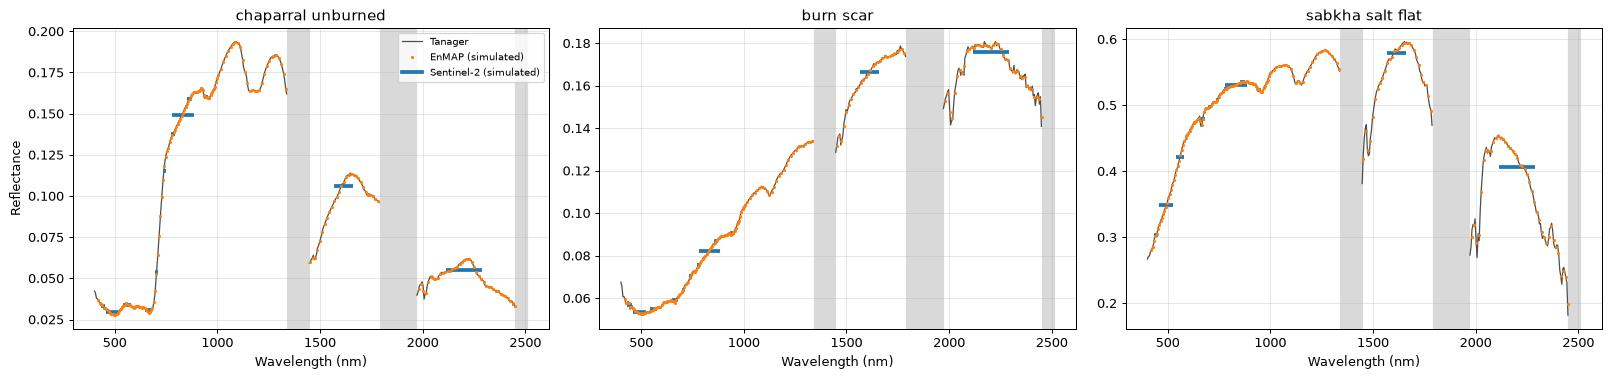

In [17]:
wl_lib, lib, _ = hu.load_library()
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3), sharey=False)
for ax, name in zip(axes, ["chaparral_unburned", "burn_scar", "sabkha_salt_flat"]):
    s = lib[name]
    hu.plot_spectrum(ax, wl_lib, s, color="0.3", lw=1, label="Tanager")
    s2v = hu.resample_to_sensor(wl_lib, s, s2_c, s2_w)
    for (c, w), v in zip(zip(s2_c, s2_w), s2v):
        ax.plot([c - w / 2, c + w / 2], [v, v], color="tab:blue", lw=3, solid_capstyle="butt")
    en = hu.resample_to_sensor(wl_lib, s, hu.ENMAP_APPROX["centers"], hu.ENMAP_APPROX["fwhm"])
    ax.plot(hu.ENMAP_APPROX["centers"], en, ".", ms=3, color="tab:orange", label="EnMAP (simulated)")
    ax.plot([], [], color="tab:blue", lw=3, label="Sentinel-2 (simulated)")
    hu.shade_bad_regions(ax); ax.set_title(name.replace("_", " ")); ax.set_xlabel("Wavelength (nm)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Reflectance"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [18]:
# Pixel-level comparison over the post-fire scene (stride 3 → ~110 000 pixels, all land-cover types)
cube_s, wl = post.read_cube(stride=3)
X, okmask = hu.cube_to_pixels(cube_s)
g, n_ = X[:, hu.band_index(wl, 560)], X[:, hu.band_index(wl, 860)]
X = X[hu.nd(g, n_) < 0]                     # land only
print("land pixels compared:", len(X))

sims = {
    "Tanager": (X, wl),
    "Sentinel-2": (hu.resample_to_sensor(wl, X, s2_c, s2_w), np.array(s2_c)),
    "Landsat 8/9": (hu.resample_to_sensor(wl, X, [v[0] for v in hu.LANDSAT8_BANDS.values()],
                                          [v[1] for v in hu.LANDSAT8_BANDS.values()]),
                    np.array([v[0] for v in hu.LANDSAT8_BANDS.values()])),
    "EnMAP": (hu.resample_to_sensor(wl, X, hu.ENMAP_APPROX["centers"], hu.ENMAP_APPROX["fwhm"]),
              hu.ENMAP_APPROX["centers"]),
}
# band choices per sensor (closest to the nominal wavelengths; S2 uses B8A, the narrow NIR band)
def idx(sensor, nm):
    return int(np.argmin(np.abs(sims[sensor][1] - nm)))
indices = {}
for sensor, (Y, c) in sims.items():
    nir = Y[:, idx(sensor, 860)]
    indices[sensor] = {
        "NDVI": hu.nd(nir, Y[:, idx(sensor, 665)]),
        "NBR": hu.nd(nir, Y[:, idx(sensor, 2200)]),
        "NDMI": hu.nd(nir, Y[:, idx(sensor, 1610)]),
    }

rows = []
for sensor in ("Sentinel-2", "Landsat 8/9", "EnMAP"):
    for name in ("NDVI", "NBR", "NDMI"):
        t, o = indices["Tanager"][name], indices[sensor][name]
        ok = np.isfinite(t) & np.isfinite(o)
        slope, icpt = np.polyfit(t[ok], o[ok], 1)
        rows.append(dict(sensor=sensor, index=name, bias=np.mean(o[ok] - t[ok]),
                         rmse=np.sqrt(np.mean((o[ok] - t[ok]) ** 2)),
                         r2=np.corrcoef(t[ok], o[ok])[0, 1] ** 2, slope=slope, intercept=icpt))
harm = pd.DataFrame(rows).round(4)
harm

land pixels compared: 41577


,sensor,index,bias,rmse,r2,slope,intercept
0,Sentinel-2,NDVI,-0.0111,0.0127,0.9987,0.9860,-0.0061
1,Sentinel-2,NBR,0.0247,0.0309,0.9972,1.0424,0.0223
2,Sentinel-2,NDMI,0.0053,0.0065,0.9996,1.0069,0.0058
3,Landsat 8/9,NDVI,-0.0116,0.0156,0.9970,0.9657,0.0005
4,Landsat 8/9,NBR,0.0262,0.0325,0.9970,1.0441,0.0238
5,Landsat 8/9,NDMI,0.0068,0.0079,0.9996,1.0079,0.0074
6,EnMAP,NDVI,-0.0042,0.0044,0.9999,0.9982,-0.0035
7,EnMAP,NBR,-0.0015,0.0037,0.9998,0.9996,-0.0015
8,EnMAP,NDMI,0.0016,0.0032,0.9998,1.0041,0.0019


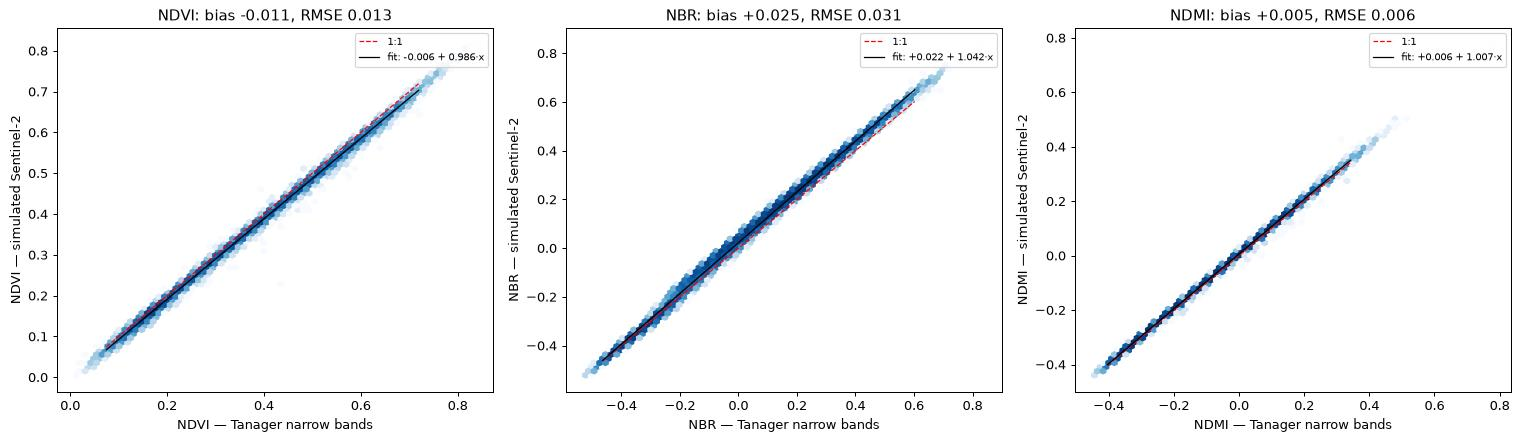

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, name in zip(ax, ("NDVI", "NBR", "NDMI")):
    t, o = indices["Tanager"][name], indices["Sentinel-2"][name]
    ok = np.isfinite(t) & np.isfinite(o)
    a.hexbin(t[ok], o[ok], gridsize=70, bins="log", cmap="Blues")
    lo, hi = np.percentile(t[ok], [0.5, 99.5]); a.plot([lo, hi], [lo, hi], "r--", lw=1, label="1:1")
    r = harm[(harm.sensor == "Sentinel-2") & (harm["index"] == name)].iloc[0]
    a.plot([lo, hi], [r.intercept + r.slope * lo, r.intercept + r.slope * hi], "k-", lw=1,
           label=f"fit: {r.intercept:+.3f} + {r.slope:.3f}·x")
    a.set_xlabel(f"{name} — Tanager narrow bands"); a.set_ylabel(f"{name} — simulated Sentinel-2")
    a.set_title(f"{name}: bias {r.bias:+.3f}, RMSE {r.rmse:.3f}"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

Even with **identical pixels and no atmospheric differences**, bandpass differences alone shift the indices by a few
hundredths, and the shift depends on land cover. For EnMAP the shift is small, because its bands are narrow. For the
broadband sensors it is not. A threshold such as "dNBR > 0.27" therefore selects a slightly different set of pixels on each sensor.

This is why operational products such as NASA's Harmonized Landsat-Sentinel (HLS; Claverie et al., 2018) apply a
**bandpass adjustment**, a per-band linear transfer function like the fits above. Does the difference matter for the
burned area? We computed the simulated Sentinel-2 NBR for both dates during the tiled pass:

In [20]:
dnbr_s2 = np.where(land, cva["nbr_s2_pre"] - cva["nbr_s2_post"], np.nan)
ok = np.isfinite(dnbr) & np.isfinite(dnbr_s2)
for thr in (0.10, 0.27, 0.44):
    a_t = (dnbr[ok] > thr).sum() * 0.09; a_s = (dnbr_s2[ok] > thr).sum() * 0.09
    agree = ((dnbr[ok] > thr) == (dnbr_s2[ok] > thr)).mean() * 100
    print(f"dNBR > {thr:.2f}: Tanager {a_t:7.0f} ha | simulated S2 {a_s:7.0f} ha "
          f"({(a_s - a_t) / a_t * 100:+5.1f}%) | pixel agreement {agree:.1f}%")

dNBR > 0.10: Tanager    5215 ha | simulated S2    5273 ha ( +1.1%) | pixel agreement 98.1%
dNBR > 0.27: Tanager    2836 ha | simulated S2    2894 ha ( +2.1%) | pixel agreement 99.2%
dNBR > 0.44: Tanager    2078 ha | simulated S2    2192 ha ( +5.5%) | pixel agreement 98.8%


### Optional: compare with a real Sentinel-2 L2A image

The simulation isolates the bandpass effect. A **real** Sentinel-2 image adds everything else: a different
atmospheric correction, acquisition time, viewing geometry and geolocation. The cell below downloads a Sentinel-2 L2A
scene from Microsoft Planetary Computer near the January date, reprojects B8A and B12 onto our 30 m grid with
*average* resampling, and compares NBR.

It needs internet access and the `pystac-client` and `planetary-computer` packages, so it is off by default. Set `FETCH_SENTINEL2 = True` to run it.

In [21]:
FETCH_SENTINEL2 = False   # set to True to run (internet + pystac-client + planetary-computer)

if FETCH_SENTINEL2:
    import planetary_computer, pystac_client, rasterio
    catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                        modifier=planetary_computer.sign_inplace)
    lon, lat = post.rowcol_to_lonlat(np.array([win_post[0], win_post[1]]), np.array([win_post[2], win_post[3]]))
    bbox = [lon.min(), lat.min(), lon.max(), lat.max()]
    items = list(catalog.search(collections=["sentinel-2-l2a"], bbox=bbox, datetime="2025-01-13/2025-02-02",
                                query={"eo:cloud_cover": {"lt": 30}}).items())
    # a tile can be only partly covered by one orbit: skip items that are mostly no-data
    items = [it for it in items if it.properties.get("s2:nodata_pixel_percentage", 0) < 10]
    items.sort(key=lambda it: abs(pd.Timestamp(it.datetime).tz_convert(None) - pd.Timestamp("2025-01-23")))

    def read_s2(item, band, resampling=Resampling.average):
        """One L2A band on our 30 m grid (average of the 20 m pixels)."""
        with rasterio.open(item.assets[band].href) as src:
            dst = np.full((H, W), np.nan, "float32")
            reproject(rasterio.band(src, 1), dst, dst_transform=post.transform(win_post), dst_crs=post.crs,
                      src_nodata=0, dst_nodata=np.nan, resampling=resampling)
        return dst

    # take the closest date whose clear (not cloud/shadow in the SCL layer) pixels cover most of our land
    for item in items:
        scl = read_s2(item, "SCL", Resampling.nearest)
        clear = np.isfinite(scl) & ~np.isin(scl, [3, 8, 9, 10])   # 3 shadow, 8/9 cloud, 10 cirrus
        print(f"{item.id}: {clear[land].mean() * 100:.0f}% of our land clear")
        if clear[land].mean() > 0.7:
            break
    baseline = float(item.properties.get("s2:processing_baseline", "0"))
    offset = -0.1 if baseline >= 4.0 else 0.0     # since baseline 04.00 (Jan 2022) L2A has a −1000 DN offset
    s2_real = {b: np.where(clear, read_s2(item, b) / 10000.0 + offset, np.nan) for b in ("B8A", "B12")}
    print("using", item.id)
    nbr_s2_real = hu.nd(s2_real["B8A"], s2_real["B12"])
    ok = land & np.isfinite(nbr_s2_real) & np.isfinite(nbr_post)
    diff = nbr_s2_real[ok] - nbr_post[ok]
    print(f"NBR real S2 − Tanager (land): bias {diff.mean():+.3f}, RMSE {np.sqrt((diff ** 2).mean()):.3f}, "
          f"r² {np.corrcoef(nbr_s2_real[ok], nbr_post[ok])[0, 1] ** 2:.3f}")
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    ax[0].imshow(np.where(land, nbr_s2_real, np.nan), cmap="RdYlGn", vmin=-0.4, vmax=0.7); ax[0].set_title("Sentinel-2 NBR")
    ax[1].hexbin(nbr_post[ok], nbr_s2_real[ok], gridsize=60, bins="log", cmap="Blues"); ax[1].plot([-0.5, 0.8], [-0.5, 0.8], "r--")
    ax[1].set_xlabel("Tanager NBR"); ax[1].set_ylabel("Sentinel-2 NBR"); plt.tight_layout(); plt.show()
else:
    print("Skipped (FETCH_SENTINEL2 = False)")

Skipped (FETCH_SENTINEL2 = False)


## 9. Scaling up: processing a whole scene with bounded memory

Everything so far used windows. A complete Tanager cube is 426 × ~1000 × ~950 values, **about 1.7 GB in float32**.
That fits in memory on a good laptop, but not on a free Colab instance, and it certainly does not scale to a time
series of 50 scenes. The standard answer is **tiling**: read a block, process it, write the result, move on.
Peak memory then depends on the tile size, not on the scene size.

Two practical details:
- **Tile along the file's chunks.** The HDF5 cube is stored in compressed chunks of 14 bands × 44 rows × 49 columns.
  A tile that cuts through a chunk still decompresses the whole chunk, so moderately large tiles (128–256 px) that
  read all bands at once are efficient.
- **Keep the per-tile function pure** (inputs → outputs, no global state). The same function then runs unchanged in
  a loop, in parallel, or inside dask.

Below we compute two full-scene products for the complete January scene: NBR, and the spectral angle to the
library "burn scar" spectrum. The spectral angle needs every band of every pixel.

full scene 1063×957 px × 426 bands processed in 8.3 s
peak memory allocated during the run: 0.24 GB (the full float32 cube alone would need 1.73 GB)


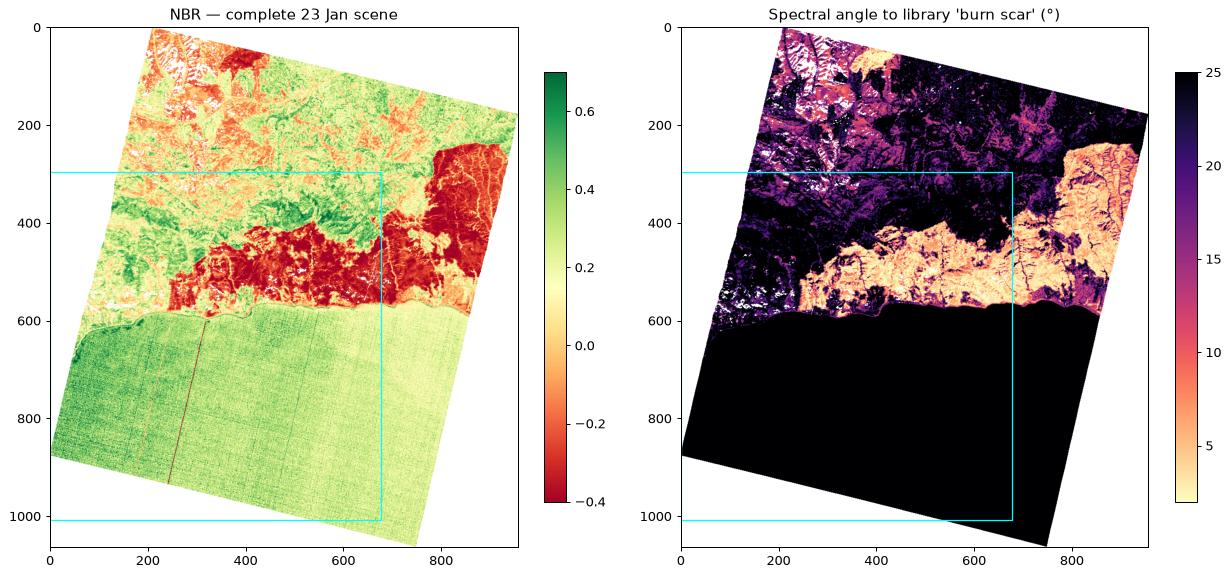

In [22]:
import tracemalloc
del cube_s, X, sims            # free the arrays from section 8 before measuring memory

def process_tiled(scene, func, tile=192, n_out=2):
    """Apply func(cube, wl, valid) → list of 2-D arrays to every tile of a scene."""
    _, nrows, ncols = scene.shape
    out = [np.full((nrows, ncols), np.nan, "float32") for _ in range(n_out)]
    for r0 in range(0, nrows, tile):
        for c0 in range(0, ncols, tile):
            win = (r0, min(r0 + tile, nrows), c0, min(c0 + tile, ncols))
            valid_t = scene.valid_mask(win)
            if not valid_t.any():
                continue          # skip empty tiles (the rotated footprint leaves many)
            cube, wl = scene.read_cube(win)
            for o, res in zip(out, func(cube, wl, valid_t)):
                o[win[0]:win[1], win[2]:win[3]] = res
    return out

ref = lib["burn_scar"]
def burn_products(cube, wl, valid_t):
    nbr = hu.nd(cube[hu.band_index(wl, 860)], cube[hu.band_index(wl, 2200)])
    r = np.interp(wl, wl_lib[np.isfinite(ref)], ref[np.isfinite(ref)])
    X = cube.reshape(len(wl), -1).T
    sam = np.degrees(hu.spectral_angle(np.nan_to_num(X), r)).reshape(cube.shape[1:])
    sam[~valid_t] = np.nan
    return nbr, sam

tracemalloc.start()                       # tracks numpy allocations too
t0 = time.perf_counter()
nbr_full, sam_full = process_tiled(post, burn_products)
dt = time.perf_counter() - t0
_, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()
full_cube_gb = np.prod(post.shape) * 4 / 1e9
print(f"full scene {post.shape[1]}×{post.shape[2]} px × {post.shape[0]} bands processed in {dt:.1f} s")
print(f"peak memory allocated during the run: {peak / 1e9:.2f} GB "
      f"(the full float32 cube alone would need {full_cube_gb:.2f} GB)")

fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
im0 = ax[0].imshow(nbr_full, cmap="RdYlGn", vmin=-0.4, vmax=0.7); ax[0].set_title("NBR — complete 23 Jan scene")
plt.colorbar(im0, ax=ax[0], fraction=0.04)
im1 = ax[1].imshow(sam_full, cmap="magma_r", vmin=2, vmax=25); ax[1].set_title("Spectral angle to library 'burn scar' (°)")
plt.colorbar(im1, ax=ax[1], fraction=0.04)
for a in ax:
    a.add_patch(Rectangle((win_post[2], win_post[0]), W, H, fill=False, ec="cyan", lw=1))
plt.tight_layout(); plt.show()

The cyan box marks the overlap we analysed. The full January scene shows that the Palisades burn scar **continues
far to the east**, beyond the December footprint, with low NBR and a small angle to the library burn-scar spectrum.
Only the part inside the box could be assessed bi-temporally. The rest needs another "before" image, which you can
find with notebook `16_scene_finder`.

### Lazy processing with dask (optional)

[dask](https://www.dask.org) builds a *task graph* over chunked arrays and runs it lazily, in parallel and out-of-core.
You can wrap the HDF5 dataset directly. Note `lock=True`: h5py does not allow concurrent reads from several threads.

In [23]:
try:
    import dask.array as da
    ds = post._fields["surface_reflectance"]                         # the h5py dataset, nothing read yet
    cube_lazy = da.from_array(ds, chunks=(ds.shape[0], 256, 256), lock=True)
    nir, swir = cube_lazy[post.band_index(860)], cube_lazy[post.band_index(2200)]
    nbr_lazy = (nir - swir) / (nir + swir + 1e-6)                    # still lazy: a task graph
    print(nbr_lazy)
    t0 = time.perf_counter()
    nbr_dask = nbr_lazy.compute()
    print(f"computed in {time.perf_counter() - t0:.1f} s")
    same = np.isclose(nbr_dask, nbr_full, equal_nan=True) | ~post.valid_mask()
    print("identical to the tiled numpy result on valid pixels:", bool(same.all()))
except ImportError:
    print("dask is not installed — `pip install dask` to try this cell")

dask.array<truediv, shape=(1063, 957), dtype=float32, chunksize=(256, 256), chunktype=numpy.ndarray>


computed in 5.6 s
identical to the tiled numpy result on valid pixels: True


**Rules of thumb for scaling your project**

| Situation | Approach |
|---|---|
| One scene, a few bands | Read the bands directly (`scene.read_band`) |
| One scene, full spectra | Tiles of 128–256 px with all bands (as above) |
| Many scenes | Loop over scenes, run the tiled function per scene, write COGs, and don't keep cubes in memory |
| Many scenes, many cores | Run scenes in parallel as separate processes (`concurrent.futures.ProcessPoolExecutor`) or with dask |
| Repeated analysis of the same area | Save an analysis-ready subset once (`hu.write_subset`) and work from that |

## 10. Solution refinement: error analysis and sensitivity

The first version of any product is rarely the best. Refinement is a loop of **three questions**:

1. **How sensitive is the result to my choices?** (thresholds, masks, band choices)
2. **Where are the errors, and why?** (look at the errors, not only at the accuracy numbers)
3. **Which targeted fix removes the largest error, and did it help?** (measure before and after)

### 10.1 Threshold sensitivity

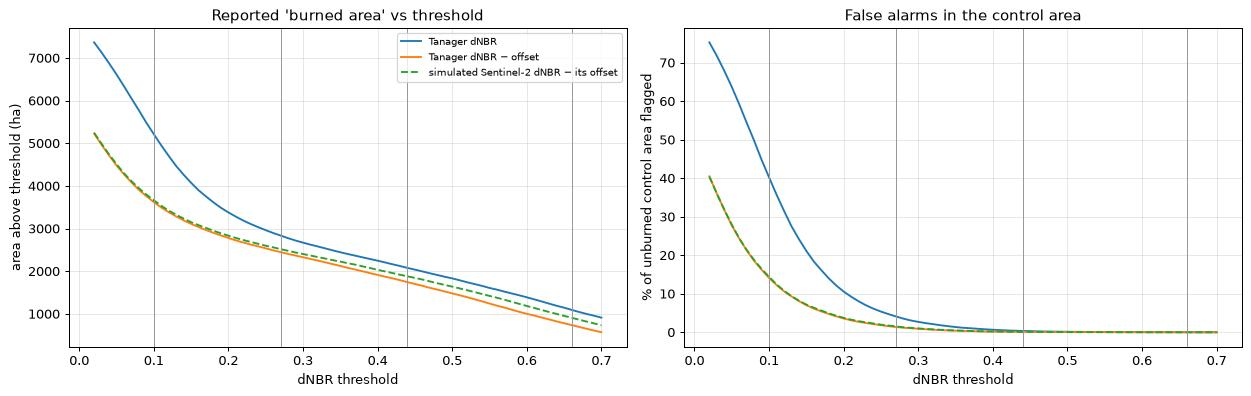

Tanager dNBR                            :   5215 ha above 0.10 |   2836 ha above 0.27
Tanager dNBR − offset                   :   3621 ha above 0.10 |   2447 ha above 0.27
simulated Sentinel-2 dNBR − its offset  :   3665 ha above 0.10 |   2518 ha above 0.27


In [24]:
dnbr_s2_offset = float(np.nanmedian(dnbr_s2[control]))
curves = {"Tanager dNBR": dnbr, "Tanager dNBR − offset": dnbr - dnbr_offset,
          "simulated Sentinel-2 dNBR − its offset": dnbr_s2 - dnbr_s2_offset}
thr = np.linspace(0.02, 0.7, 69)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for (name, d), ls in zip(curves.items(), ("-", "-", "--")):
    ax[0].plot(thr, [(d > t).sum() * 0.09 for t in thr], ls, label=name)
    ax[1].plot(thr, [np.mean(d[control] > t) * 100 for t in thr], ls, label=name)
for a in ax:
    for t in (0.10, 0.27, 0.44, 0.66):
        a.axvline(t, color="0.6", lw=0.8)
    a.set_xlabel("dNBR threshold"); a.grid(alpha=0.3)
ax[0].set_ylabel("area above threshold (ha)"); ax[0].set_title("Reported 'burned area' vs threshold"); ax[0].legend(fontsize=8)
ax[1].set_ylabel("% of unburned control area flagged"); ax[1].set_title("False alarms in the control area")
plt.tight_layout(); plt.show()
for name, d in curves.items():
    print(f"{name:40s}: {(d > 0.10).sum() * 0.09:6.0f} ha above 0.10 | {(d > 0.27).sum() * 0.09:6.0f} ha above 0.27")

Two things to take from these curves:

- **The threshold matters, especially below ~0.25.** Between the "Low" (0.10) and "Moderate-low" (0.27) thresholds the
  reported area changes by thousands of hectares, because every small step adds a wide fringe of weakly changed pixels.
  Above ~0.3 the area falls more slowly: that is the core of the scar. Report burned area **with the range** that
  reasonable thresholds give, not as a single number.
- **The offset mostly affects the low-severity class.** Without it, about 40 % of the unburned control area is flagged at
  0.10; with it, about 14 %. At 0.27 the effect is smaller, because 0.27 is already well above the offset.

### 10.2 Where are the errors?

We have no official burn perimeter in the notebook (see exercise 2), but we do have the **control area**, where any
detection is by construction a false alarm. What distinguishes those false alarms from the rest of the control area?

In [25]:
edge = ndimage.binary_dilation(~land, iterations=2) & land              # next to water / no-data
shadow = land & (b_post["nir"] < np.nanpercentile(b_post["nir"][land], 10))   # darkest 10% in January
brighter_all = (cva["d_vis"] > 0) & (cva["d_nir"] > 0) & (cva["d_swir2"] > 0)

def profile(mask):
    return {"pixels": int(mask.sum()), "brighter in all bands %": brighter_all[mask].mean() * 100,
            "burn-like direction %": (direction[mask] == 0).mean() * 100,
            "next to water/no-data %": edge[mask].mean() * 100, "deep shadow %": shadow[mask].mean() * 100,
            "median CVA angle (°)": np.nanmedian(cva["angle"][mask])}

fa_low = control & (dnbr > 0.10)        # 'burned' at the Low threshold, without offset
fa_mod = control & (dnbr > 0.27)
prof = pd.DataFrame({"all control pixels": profile(control), "false alarms, dNBR > 0.10": profile(fa_low),
                     "false alarms, dNBR > 0.27": profile(fa_mod), "main new scar": profile(new_burn)}).T.round(1)
prof

,pixels,brighter in all bands %,burn-like direction %,next to water/no-data %,deep shadow %,median CVA angle (°)
all control pixels,52444.0,80.4,6.3,12.3,4.1,6.3
"false alarms, dNBR > 0.10",21106.0,85.6,12.9,12.1,3.3,8.4
"false alarms, dNBR > 0.27",2156.0,83.7,16.0,21.4,3.5,15.3
main new scar,28115.0,15.2,84.6,13.8,19.6,30.2


At the **0.10** threshold the false alarms look like the control area as a whole: mostly brighter in all bands, rarely
burn-like, with only a small change in spectral shape. They are the systematic brightening from section 6, which is exactly
what the dNBR offset removes.

At the **0.27** threshold the remaining false alarms are different:
- they are over-represented **next to water or no-data** (mixed coastal pixels and mask edges);
- they have a clearly larger change in spectral **shape** (a larger CVA angle). Some may be real, small changes, such as
  clearing, construction or a spot fire, which we cannot confirm without reference data;
- **deep shadow**, often a culprit in mountainous terrain, is *not* over-represented here.

### 10.3 Refine and measure

Now we add the fixes **one at a time** and measure each one with the same two numbers: false alarms in the unburned
control area (lower is better) and the share of the scar interior that is still detected (higher is better).

1. co-registration (section 2)
2. dNBR offset (section 6)
3. significance against the total uncertainty (section 7)
4. a burn-like CVA direction (section 5)
5. a minimum mapping unit of 10 pixels (0.9 ha)

In [26]:
core = ndimage.binary_erosion(new_burn, iterations=3)       # interior of the main scar
dnbr_raw = np.where(land & land_raw, nbr_pre - hu.nd(b_post_raw["nir"], b_post_raw["swir2"]), np.nan)

def mmu(mask, min_px=10):
    lab, n = ndimage.label(mask)
    if n == 0:
        return mask
    sizes = ndimage.sum(mask, lab, index=np.arange(1, n + 1))
    return np.isin(lab, np.nonzero(sizes >= min_px)[0] + 1)

THR = 0.27
steps = {}
steps["0 naive: dNBR > 0.27, no co-registration"] = np.nan_to_num(dnbr_raw) > THR
steps["1 + co-registration"] = np.nan_to_num(dnbr) > THR
steps["2 + dNBR offset"] = np.nan_to_num(dev) > THR
steps["3 + significant vs total σ"] = steps["2 + dNBR offset"] & sig_total
steps["4 + burn-like CVA direction"] = steps["3 + significant vs total σ"] & (direction == 0)
steps["5 + minimum mapping unit (10 px)"] = mmu(steps["4 + burn-like CVA direction"])

rows = []
for name, m in steps.items():
    rows.append({"step": name, "area (ha)": round(m.sum() * 0.09), "clusters": ndimage.label(m)[1],
                 "control false alarms (%)": round(m[control].mean() * 100, 2),
                 "scar interior detected (%)": round(m[core].mean() * 100, 1)})
pd.DataFrame(rows)

,step,area (ha),clusters,control false alarms (%),scar interior detected (%)
0,"0 naive: dNBR > 0.27, no co-registration",2793,1724,4.65,99.2
1,1 + co-registration,2836,1349,4.11,100.0
2,2 + dNBR offset,2447,653,1.37,98.8
3,3 + significant vs total σ,2447,653,1.37,98.8
4,4 + burn-like CVA direction,2018,373,0.20,90.1
5,5 + minimum mapping unit (10 px),1958,22,0.00,89.8


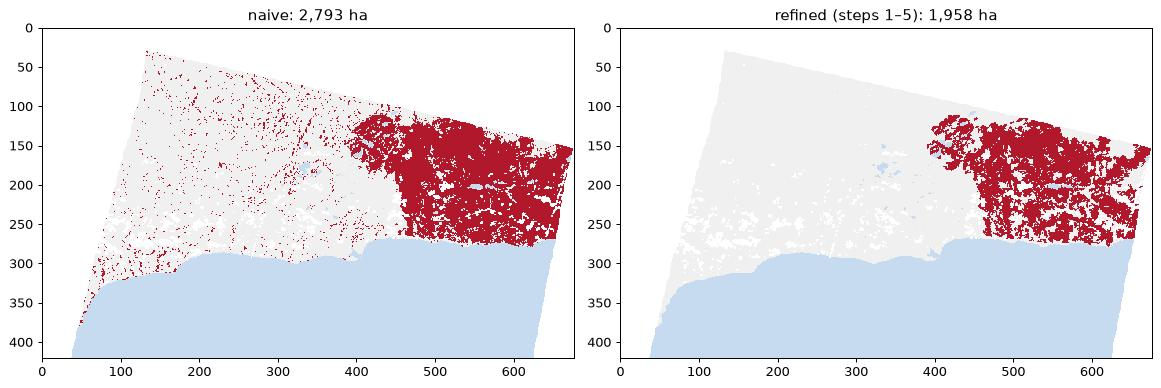

In [27]:
naive, refined = steps["0 naive: dNBR > 0.27, no co-registration"], steps["5 + minimum mapping unit (10 px)"]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, m, t in ((ax[0], naive, "naive"), (ax[1], refined, "refined (steps 1–5)")):
    show = np.where(valid, 0.0, np.nan); show[land] = 1; show[m] = 2
    a.imshow(show, cmap=ListedColormap(["#c6dbef", "#f0f0f0", "#b2182b"]), vmin=-0.5, vmax=2.5, interpolation="nearest")
    a.set_title(f"{t}: {m.sum() * 0.09:,.0f} ha"); a.set_ylim(420, 0)
plt.tight_layout(); plt.show()

Reading the table from top to bottom:
- **Co-registration** hardly changes the area, but it reduces the number of speckle clusters by about a fifth: part of the
  speckle was misregistration along ridges.
- **The dNBR offset** cuts the false alarms in the control area by about a factor of three, at almost no cost to the scar.
- **The significance test** changes nothing *at this threshold*, because 0.27 is already above 2σ_total ≈ 0.18. It matters
  for the low-severity class.
- **The direction rule** removes most of the remaining false alarms, but also about a tenth of the scar interior. Those are
  burned pixels where NIR did not drop in absolute terms, because the overall brightening of January (section 6) made up
  for the decrease. One fix would be to compute the direction on offset-corrected spectra.
- **The minimum mapping unit** removes the last isolated pixels.

There is no single "best" version. For **emergency response**, missing burned area is worse than a few false alarms, so
stop after step 2 or 3. For **area statistics**, precision matters more, so use the full chain, and report the range
between the variants (here roughly 1,950–2,850 ha at the moderate-severity level) rather than one number.

> **Caveat:** we calibrated the offset and σ on the same control area that we evaluate on, which flatters the result. In a
> real project, calibrate on one half of the control area and evaluate on the other, or better, on independent reference
> data (exercise 2).

### Refinement checklist for your project

- [ ] **Inputs**: are the images the right dates, seasons and geometry for the question? Did you look at them?
- [ ] **Masks**: did you check what the cloud/cirrus/no-data masks remove, and what they miss?
- [ ] **Alignment**: same CRS, same lattice, co-registration better than ½ pixel?
- [ ] **Sensitivity**: how much does the answer change with each threshold or parameter? Report ranges.
- [ ] **Uncertainty**: is it the uncertainty that matches your question (sensor vs. between-date vs. model)?
- [ ] **Error analysis**: did you look at *where* the errors are, and can you explain them physically?
- [ ] **Targeted fixes**: for each fix, did you measure its effect before and after on the same reference?
- [ ] **Independent check**: does an independent source (field data, official perimeter, another sensor) agree?
- [ ] **Transferability**: does it still work on a second scene, sensor or season? If not, say so.
- [ ] **Scale**: does it run on a full scene within your memory and time budget?

## ✏️ Your turn

**1. Relative severity.** dNBR depends on how much vegetation was there before the fire. Compute the relative dNBR
(Miller & Thode, 2007), $\text{RdNBR} = \text{dNBR} / \sqrt{|\text{NBR}_{\text{before}}|}$, map it, and compare the
area above 0.27 with dNBR. Where do the two disagree, and why?

<details><summary>Hint</summary>

Guard against division by (almost) zero, e.g. `np.maximum(np.sqrt(np.abs(nbr_pre)), 0.1)`. RdNBR is usually
expressed ×1000, with severity thresholds of roughly 69 / 316 / 641 (Miller & Thode, 2007).
</details>
<details><summary>Solution</summary>

```python
rdnbr = dnbr / np.maximum(np.sqrt(np.abs(nbr_pre)), 0.1)
print("area dNBR>0.27:", (dnbr > 0.27).sum() * 0.09, "ha | RdNBR>0.27:", (rdnbr > 0.27).sum() * 0.09, "ha")
plt.imshow(np.where(land, rdnbr, np.nan), cmap="RdYlGn_r", vmin=-1, vmax=1); plt.colorbar(); plt.show()
# RdNBR raises the severity of burns in sparse vegetation (small NBR_pre),
# where the absolute NBR drop is small even if most of the vegetation burned.
```
</details>

**2. Validate against the official perimeter.** Download the Palisades fire perimeter (CAL FIRE or NIFC open data,
GeoJSON/shapefile), rasterise it onto the overlap grid (`rasterio.features.rasterize` with `pre.transform(win_pre)`)
and compute precision, recall and IoU for the naive and the refined map. Which one wins, and is the official
perimeter itself "the truth"? (Perimeters include unburned islands.)

<details><summary>Hint</summary>

Reproject the perimeter to `pre.crs` with geopandas (`gdf.to_crs(pre.crs)`) and rasterise with
`out_shape=(H, W), transform=pre.transform(win_pre)`. Restrict the comparison to `land` pixels. Notebook 21 has the metric functions.
</details>
<details><summary>Solution</summary>

```python
import geopandas as gpd
from rasterio.features import rasterize
perim = gpd.read_file("palisades_perimeter.geojson").to_crs(pre.crs)
ref = rasterize(perim.geometry, out_shape=(H, W), transform=pre.transform(win_pre)).astype(bool)
for name, m in (("naive", naive), ("refined", refined)):
    tp = (m & ref & land).sum(); fp = (m & ~ref & land).sum(); fn = (~m & ref & land).sum()
    print(name, "precision", tp / (tp + fp), "recall", tp / (tp + fn), "IoU", tp / (tp + fp + fn))
```
</details>

**3. Correlated errors.** Repeat the Monte Carlo of section 7, but use **the same** random number for NIR and SWIR-2
(a fully correlated error, e.g. from the atmospheric correction). What happens to σ(dNBR), and why?

<details><summary>Solution</summary>

With $\varepsilon_N = \varepsilon_S$ both bands move in the same direction and the ratio NBR changes much less than
with independent errors: a common scaling cancels completely in a normalised difference. Replace the two
`rng.standard_normal` calls by one shared draw `e = rng.standard_normal((H, W))` and use `u["nir"] * e` and `u["swir2"] * e`.
</details>

**4. Tiling for your own product.** Reuse `process_tiled` to compute a product from your own project over a complete
scene (e.g. the red-edge position from notebook 13, or a classifier's probabilities from notebook 15/20). Record the
runtime and peak memory for tile sizes 64, 192 and 512. Which is fastest, and why?

<details><summary>Hint</summary>

Small tiles decompress each HDF5 chunk several times (chunks are 44 × 49 px) and pay Python overhead per tile.
Very large tiles use more memory without being faster.
</details>

**5. Harmonise a threshold.** Use the Sentinel-2 vs Tanager NBR fit from section 8 to convert the 0.27 dNBR
threshold into an equivalent "Sentinel-2 threshold". Does applying it make the simulated S2 burned area agree better
with Tanager's?

## Key takeaways

- **Change detection starts with geometry.** Check the CRS and pixel lattice, co-register (phase correlation), and only then
  compare pixels. Even two ortho products of the same sensor were about one pixel apart here.
- **dNBR measures change, not state**, and only between your two dates. Pick the "before" image for the question.
- **Two dates never have identical atmosphere and geometry.** Measure the systematic difference on an unchanged control
  area and correct for it (the dNBR offset); otherwise it ends up in your "low severity" class.
- **Confirm a detection several ways**: the image, the spectrum and independent knowledge. The full spectrum makes this much stronger with hyperspectral data.
- **CVA magnitude, angle and direction** separate burns from green-up and illumination effects.
- The **sensor uncertainty** is only one part of the story. For change, the between-date variability dominates, so estimate it empirically.
- **Bandpass differences** alone shift indices between sensors, so harmonise before mixing sensors or thresholds.
- **Tile** anything that needs full spectra, and keep the per-tile function pure so it scales.
- Refinement is a loop: **sensitivity → error analysis → targeted fix → measure again**. Report ranges and failure modes, not a single number.

**For your project:** in week 4, apply sections 7, 9 and 10 to your own pipeline. The refinement checklist is a good
structure for the "limitations and next steps" slide. Notebook `31_from_notebook_to_product` turns the analysis into a
reusable, tested pipeline.

**References**: Key & Benson (2006) *FIREMON: Landscape Assessment*, USDA RMRS-GTR-164 · Miller & Thode (2007) *Remote
Sens. Environ.* 109:66–80 · Malila (1980) *Change vector analysis*, LARS Symposia · Kuglin & Hines (1975) *The phase
correlation image alignment method* · Claverie et al. (2018) *Remote Sens. Environ.* 219:145–161 (HLS).

---
> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC (scenes from 2024 and 2025) · ESA WorldCover 2021 v200 — CC-BY 4.0 (used for the reference library)